# Mental Health Dataset

# **Mental Health Analysis Preprocessing**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import ( train_test_split,cross_val_score,KFold,StratifiedKFold)

from sklearn.preprocessing import (StandardScaler,MinMaxScaler,RobustScaler,OneHotEncoder, OrdinalEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_regression,
    mutual_info_classif
)

from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid", palette="viridis")

RANDOM_STATE = 42

### Mount Google Drive (Optional)
Run this cell if you want to mount Google Drive and access your dataset from there. Once mounted, change your path to point to your dataset location in Drive (e.g., `/content/drive/MyDrive/...`).

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df = pd.read_csv("/content/drive/MyDrive/enhanced_anxiety_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst Five Records:")
display(df.head())

print("\nLast Five Records:")
display(df.tail())

print("\nRandom Samples:")
display(df.sample(10, random_state=RANDOM_STATE))

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (11000, 19)

First Five Records:


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10)
0,29,Female,Artist,6.0,2.7,181,10,Yes,No,10,114,14,4,No,Yes,3,Yes,7,5.0
1,46,Other,Nurse,6.2,5.7,200,8,Yes,Yes,1,62,23,2,Yes,No,2,No,8,3.0
2,64,Male,Other,5.0,3.7,117,4,No,Yes,1,91,28,3,No,No,1,Yes,1,1.0
3,20,Female,Scientist,5.8,2.8,360,6,Yes,No,4,86,17,3,No,No,0,No,1,2.0
4,49,Female,Other,8.2,2.3,247,4,Yes,No,1,98,19,4,Yes,Yes,1,No,3,1.0



Last Five Records:


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10)
10995,23,Female,Engineer,6.1,3.1,566,9,Yes,No,8,91,28,1,Yes,Yes,1,No,3,6.0
10996,50,Other,Teacher,6.6,3.6,64,17,Yes,No,7,95,17,3,No,No,2,No,7,3.0
10997,29,Male,Nurse,6.7,6.9,159,14,No,No,8,72,16,1,Yes,Yes,2,Yes,7,4.0
10998,53,Other,Artist,5.7,2.7,248,8,No,No,4,112,28,3,Yes,Yes,1,Yes,2,4.0
10999,56,Other,Teacher,6.1,1.1,205,11,No,No,1,66,13,3,No,No,2,Yes,8,2.0



Random Samples:


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10)
107,35,Female,Engineer,7.7,4.6,561,8,No,No,10,87,27,2,No,No,2,No,9,5.0
5484,42,Other,Teacher,6.3,5.4,208,17,Yes,No,10,82,25,1,No,Yes,0,Yes,4,5.0
6998,46,Male,Scientist,5.4,0.2,367,9,No,Yes,9,93,25,3,Yes,No,6,No,2,10.0
3984,23,Female,Student,6.7,1.1,290,3,Yes,No,1,74,18,2,No,Yes,0,No,9,1.0
3111,26,Male,Teacher,6.4,3.8,36,4,Yes,Yes,3,115,26,4,No,Yes,4,No,8,1.0
4040,44,Male,Freelancer,7.5,2.6,128,8,Yes,No,2,64,24,1,No,No,0,Yes,1,3.0
3013,21,Other,Nurse,6.5,1.1,274,18,Yes,No,10,78,26,4,No,No,2,No,10,4.0
6607,57,Female,Scientist,5.8,2.9,312,5,No,No,5,70,25,4,No,Yes,1,No,6,5.0
4219,40,Female,Lawyer,6.0,1.9,466,2,Yes,No,3,113,17,5,Yes,No,2,Yes,1,4.0
8750,25,Male,Doctor,5.9,2.7,461,14,No,No,7,60,15,5,Yes,No,0,No,2,4.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                11000 non-null  int64  
 1   Gender                             11000 non-null  object 
 2   Occupation                         11000 non-null  object 
 3   Sleep Hours                        11000 non-null  float64
 4   Physical Activity (hrs/week)       11000 non-null  float64
 5   Caffeine Intake (mg/day)           11000 non-null  int64  
 6   Alcohol Consumption (drinks/week)  11000 non-null  int64  
 7   Smoking                            11000 non-null  object 
 8   Family History of Anxiety          11000 non-null  object 
 9   Stress Level (1-10)                11000 non-null  int64  
 10  Heart Rate (bpm)                   11000 non-null  int64  
 11  Breathing Rate (breaths/min)    

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,11000.0,NaN,NaN,NaN,40.241727,13.23614,18.0,29.0,40.0,51.0,64.0
Gender,11000,3,Female,3730,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,11000,13,Musician,892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Hours,11000.0,NaN,NaN,NaN,6.650691,1.227509,2.3,5.9,6.7,7.5,11.3
Physical Activity (hrs/week),11000.0,NaN,NaN,NaN,2.942136,1.827825,0.0,1.5,2.8,4.2,10.1
Caffeine Intake (mg/day),11000.0,NaN,NaN,NaN,286.09,144.813157,0.0,172.0,273.0,382.0,599.0
Alcohol Consumption (drinks/week),11000.0,NaN,NaN,NaN,9.701636,5.689713,0.0,5.0,10.0,15.0,19.0
Smoking,11000,2,Yes,5779,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family History of Anxiety,11000,2,Yes,5847,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stress Level (1-10),11000.0,NaN,NaN,NaN,5.856364,2.927202,1.0,3.0,6.0,8.0,10.0


In [6]:

print("\nMissing Values:")
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})
display(missing)

print("\nDuplicate Records:", df.duplicated().sum())

print("\nUnique Values:")
display(df.nunique().to_frame("Unique_Count"))

print("\nData Types:")
display(df.dtypes.to_frame("Data_Type"))

print("\nConstant Columns:")
constant_columns = [
    col for col in df.columns if df[col].nunique() <= 1
]
print(constant_columns)

print("\nWhitespace Check:")
for col in df.select_dtypes(include="object"):
    print(col, df[col].astype(str).str.strip().ne(df[col]).sum())





Missing Values:


,Missing_Count,Missing_Percentage
Age,0,0.0
Gender,0,0.0
Occupation,0,0.0
Sleep Hours,0,0.0
Physical Activity (hrs/week),0,0.0
Caffeine Intake (mg/day),0,0.0
Alcohol Consumption (drinks/week),0,0.0
Smoking,0,0.0
Family History of Anxiety,0,0.0
Stress Level (1-10),0,0.0



Duplicate Records: 0

Unique Values:


,Unique_Count
Age,47
Gender,3
Occupation,13
Sleep Hours,82
Physical Activity (hrs/week),100
Caffeine Intake (mg/day),600
Alcohol Consumption (drinks/week),20
Smoking,2
Family History of Anxiety,2
Stress Level (1-10),10



Data Types:


,Data_Type
Age,int64
Gender,object
Occupation,object
Sleep Hours,float64
Physical Activity (hrs/week),float64
Caffeine Intake (mg/day),int64
Alcohol Consumption (drinks/week),int64
Smoking,object
Family History of Anxiety,object
Stress Level (1-10),int64



Constant Columns:
[]

Whitespace Check:
Gender 0
Occupation 0
Smoking 0
Family History of Anxiety 0
Dizziness 0
Medication 0
Recent Major Life Event 0


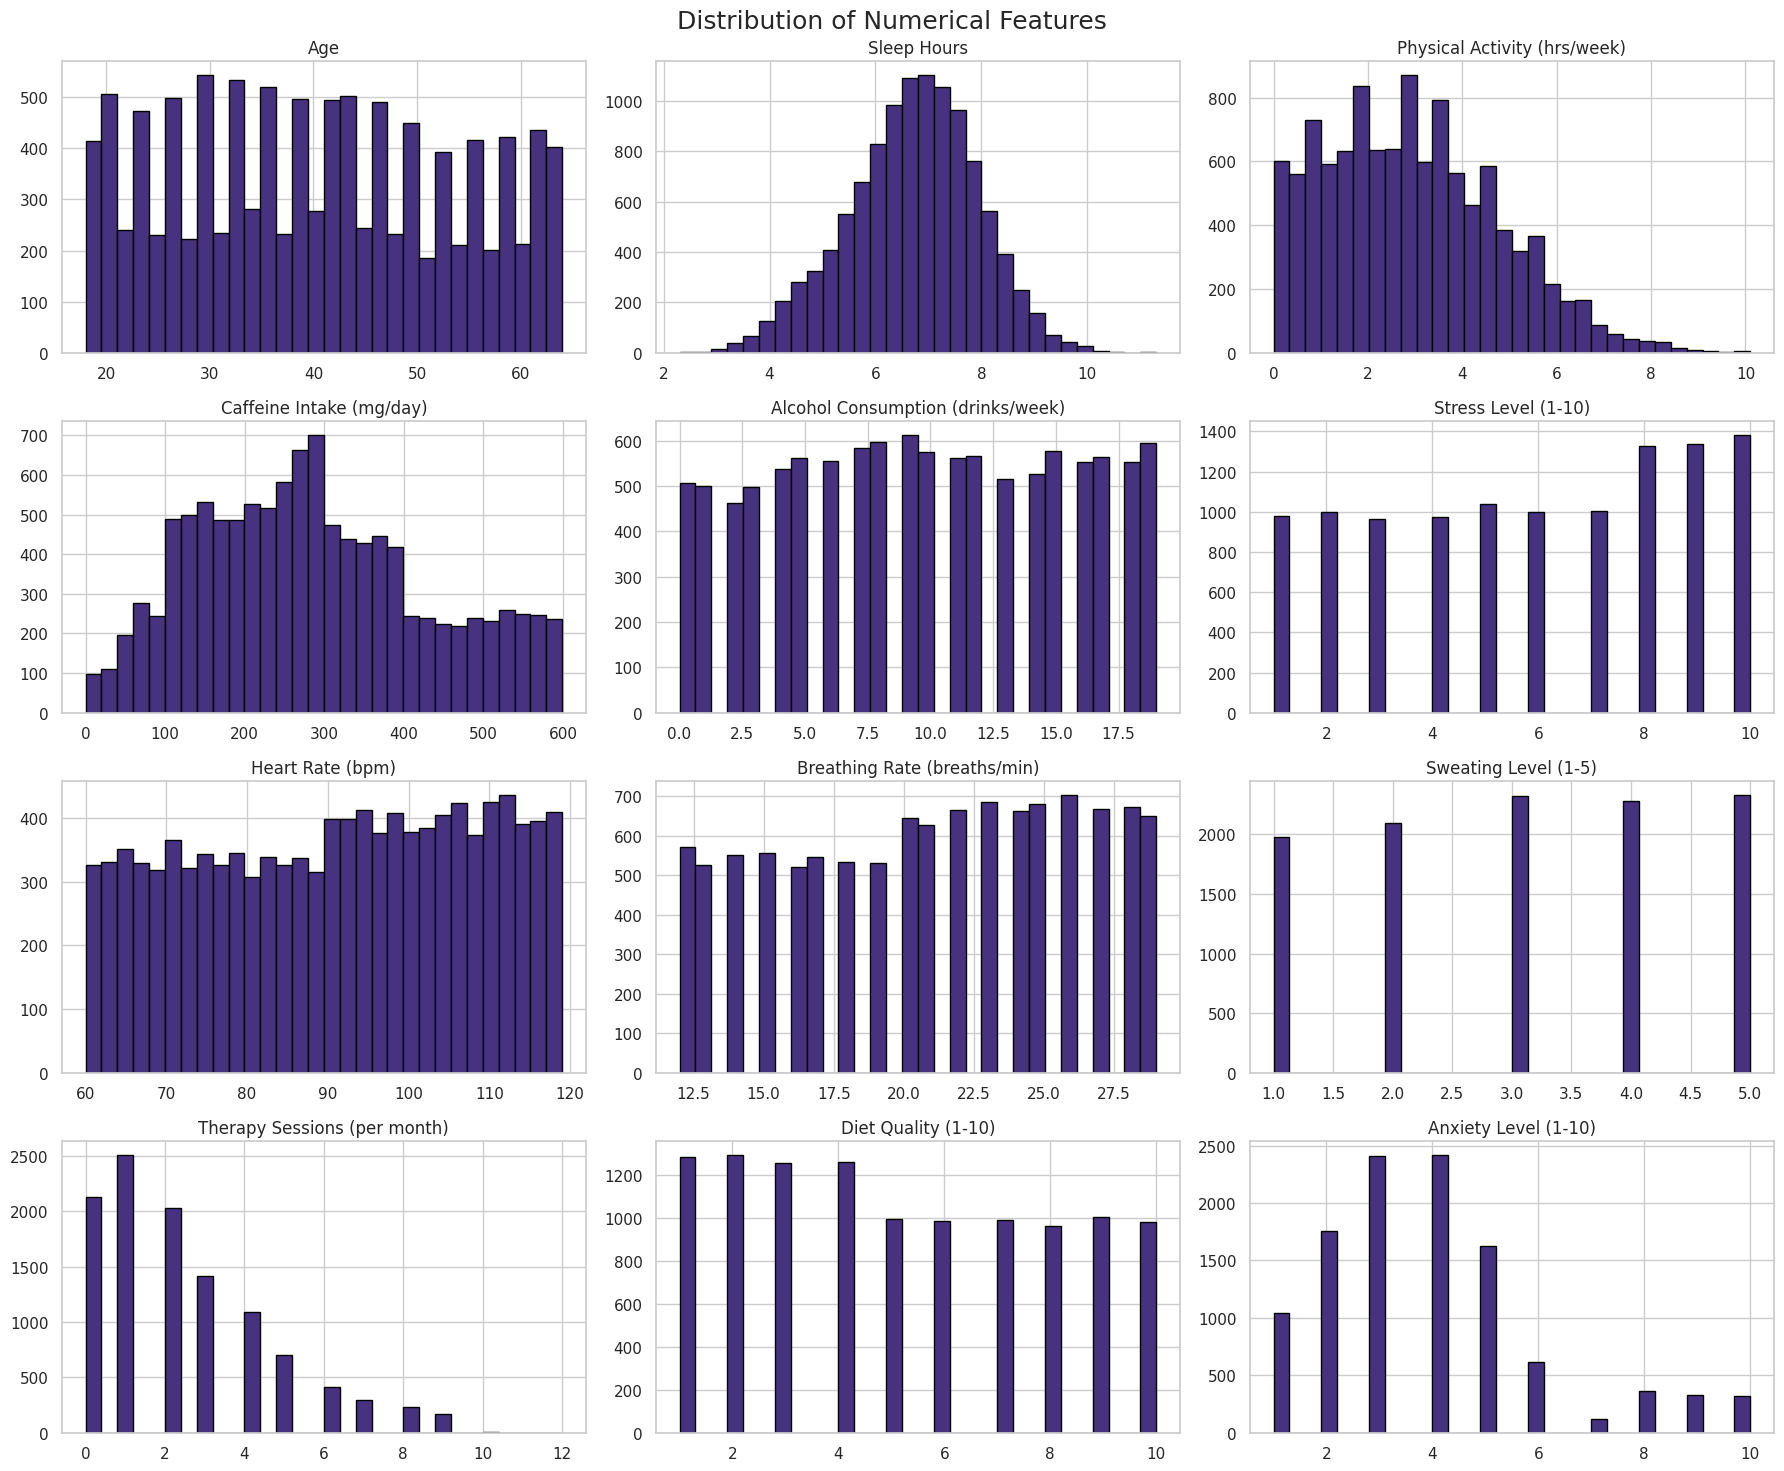

In [7]:

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

df[numerical_cols].hist(
    figsize=(18, 15),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=18)
plt.tight_layout()
plt.show()





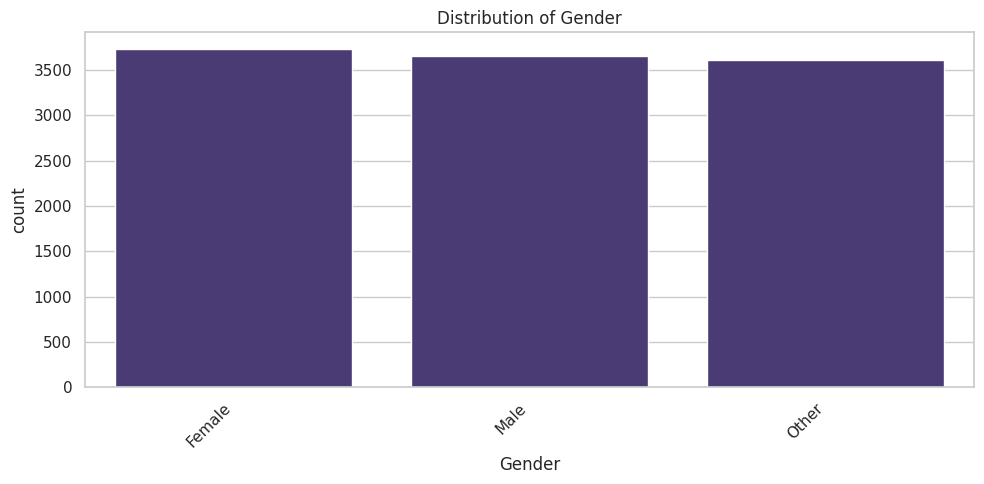


Frequency Distribution: Gender


,Count
Gender,
Female,3730
Male,3657
Other,3613


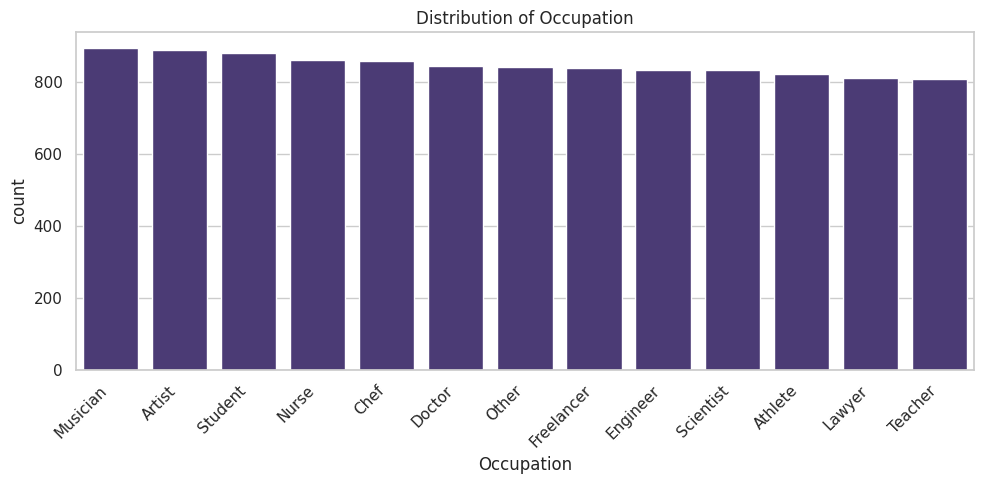


Frequency Distribution: Occupation


,Count
Occupation,
Musician,892
Artist,888
Student,878
Nurse,861
Chef,858
Doctor,842
Other,840
Freelancer,838
Engineer,833


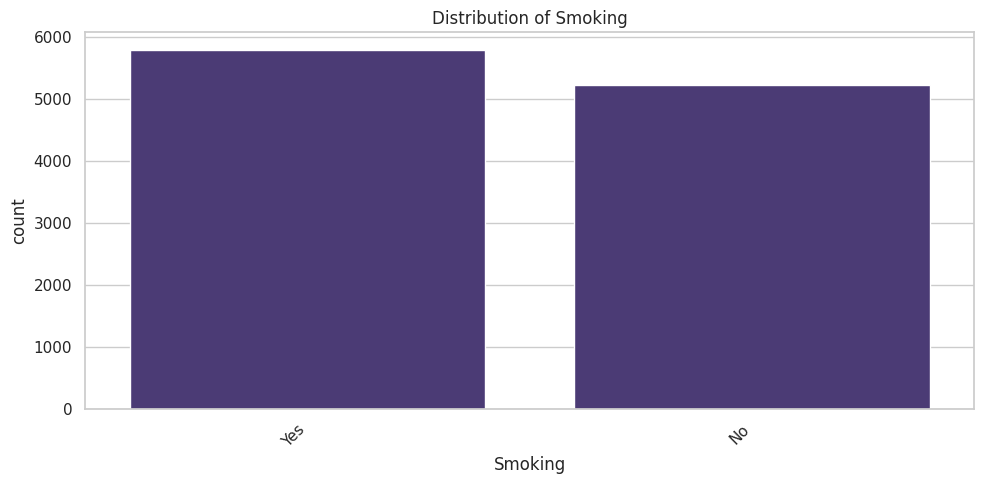


Frequency Distribution: Smoking


,Count
Smoking,
Yes,5779
No,5221


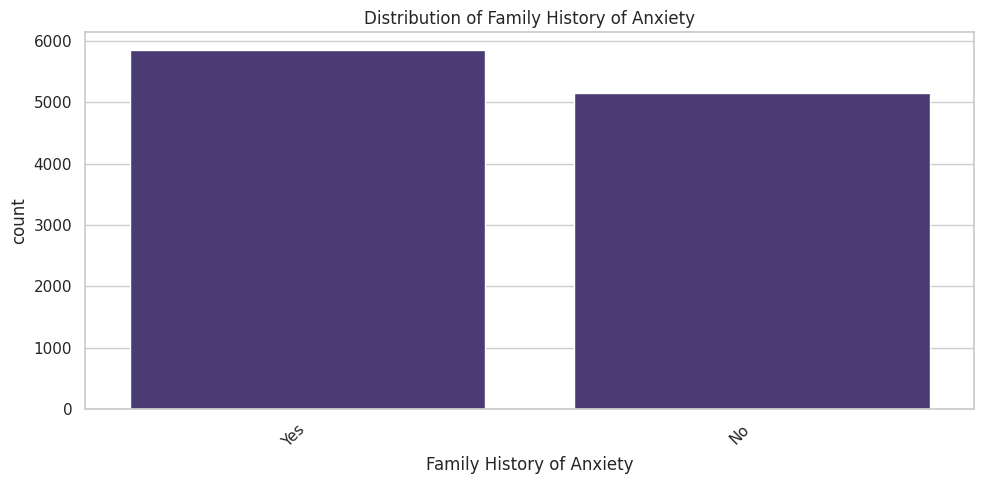


Frequency Distribution: Family History of Anxiety


,Count
Family History of Anxiety,
Yes,5847
No,5153


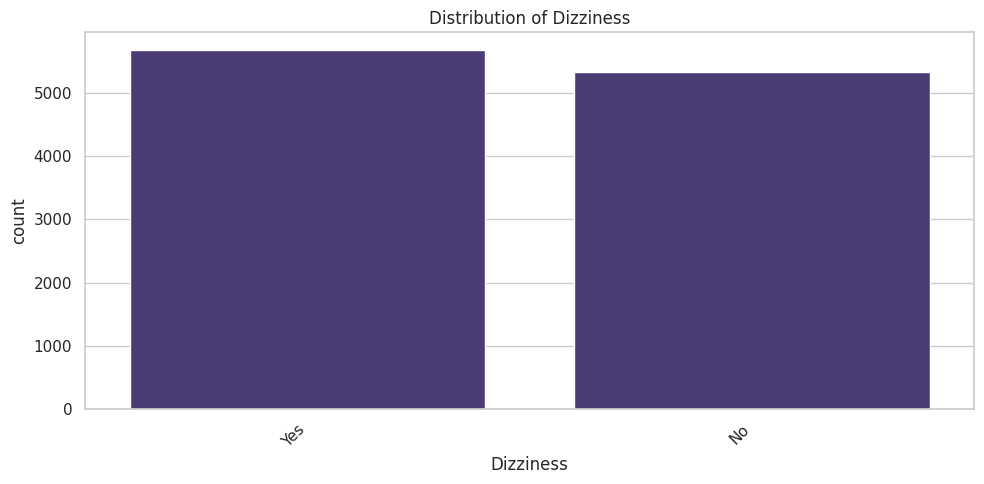


Frequency Distribution: Dizziness


,Count
Dizziness,
Yes,5672
No,5328


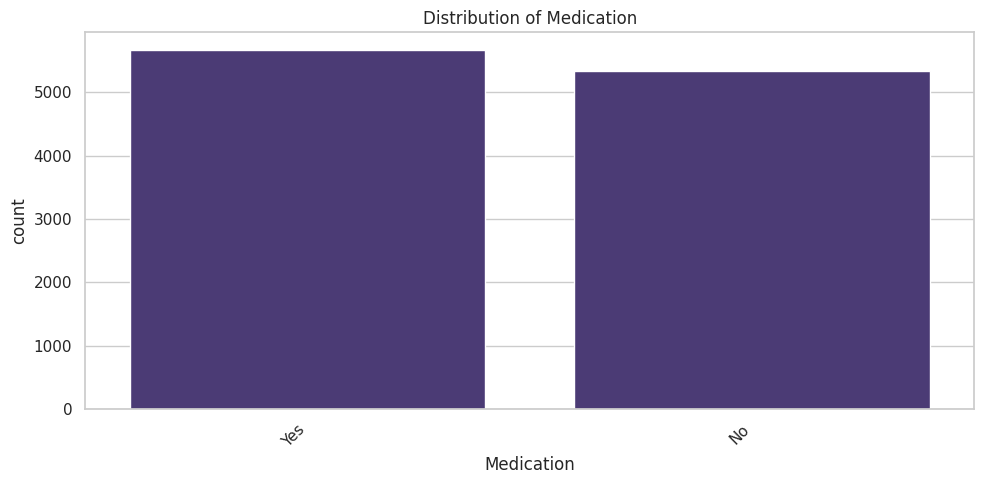


Frequency Distribution: Medication


,Count
Medication,
Yes,5666
No,5334


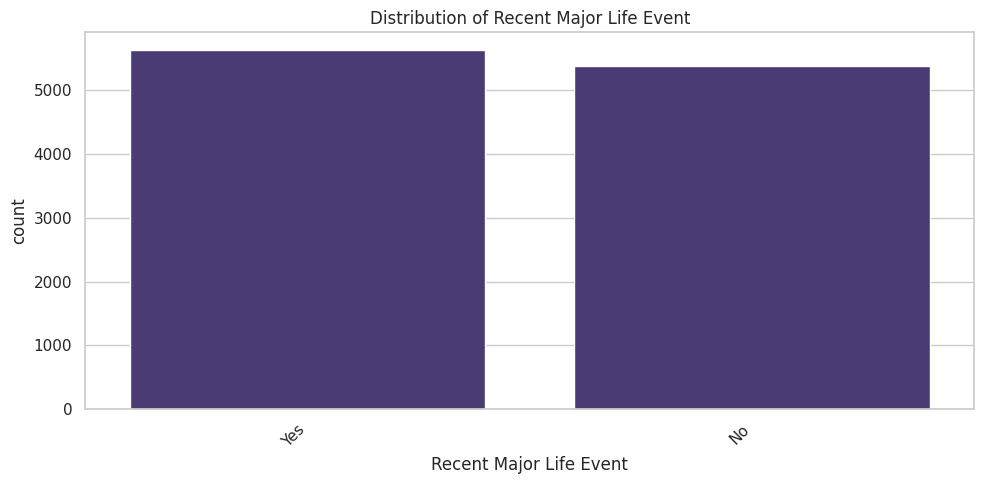


Frequency Distribution: Recent Major Life Event


,Count
Recent Major Life Event,
Yes,5623
No,5377


In [8]:


categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print(f"\nFrequency Distribution: {col}")
    display(df[col].value_counts().to_frame("Count"))

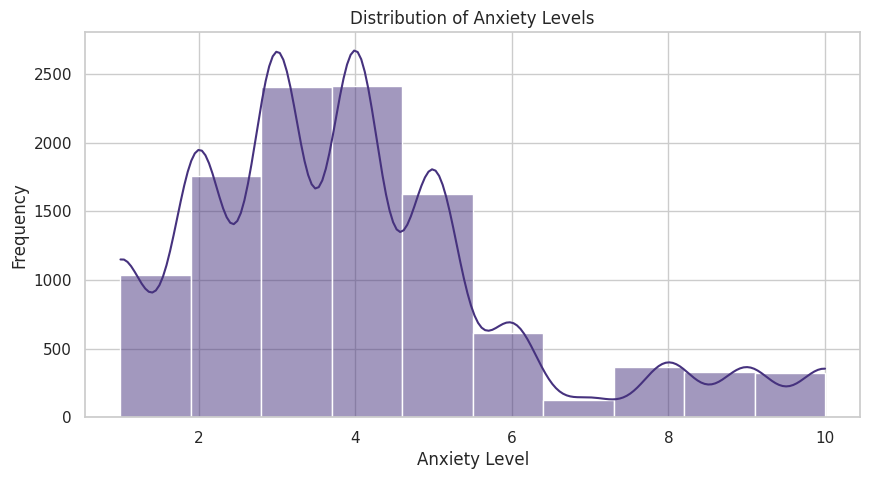

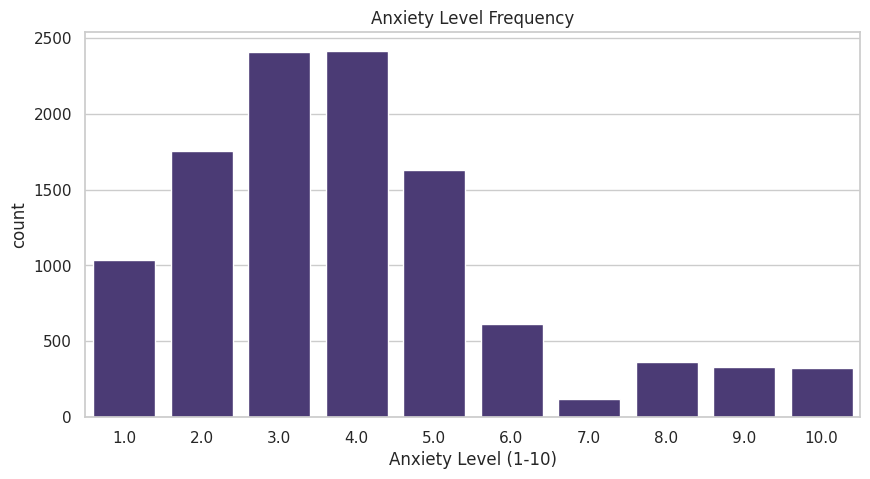

Target Statistics:


,Anxiety Level (1-10)
count,11000.000000
mean,3.929364
std,2.122533
min,1.000000
25%,2.000000
50%,4.000000
75%,5.000000
max,10.000000


Target Skewness: 1.0439964647889457
Target Kurtosis: 0.950053926739526


In [9]:



TARGET = "Anxiety Level (1-10)"

plt.figure(figsize=(10, 5))

sns.histplot(
    df[TARGET],
    bins=10,
    kde=True
)

plt.title("Distribution of Anxiety Levels")
plt.xlabel("Anxiety Level")
plt.ylabel("Frequency")
plt.show()


plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x=TARGET,
    order=sorted(df[TARGET].dropna().unique())
)

plt.title("Anxiety Level Frequency")
plt.show()


print("Target Statistics:")
display(df[TARGET].describe())

print("Target Skewness:", df[TARGET].skew())
print("Target Kurtosis:", df[TARGET].kurtosis())


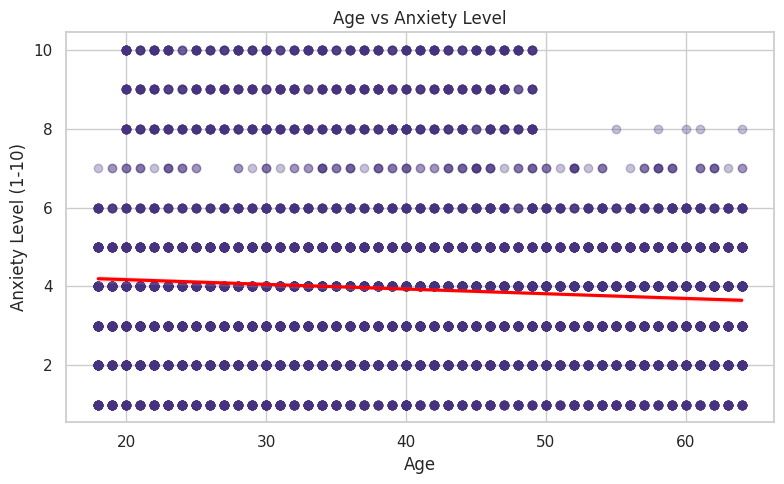

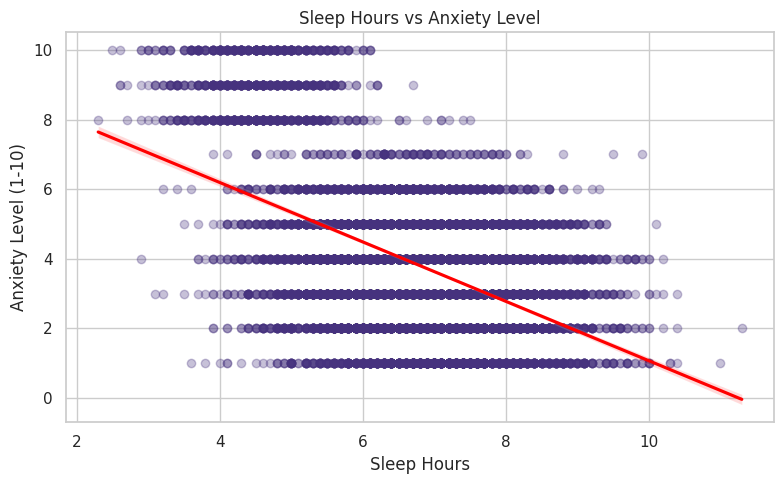

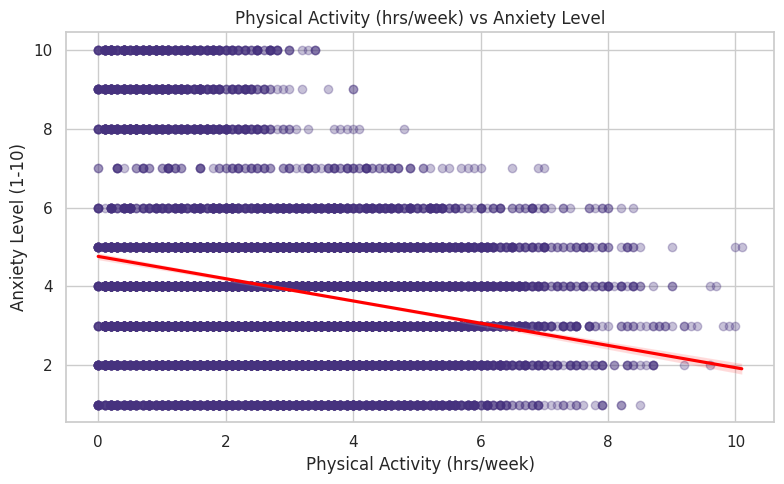

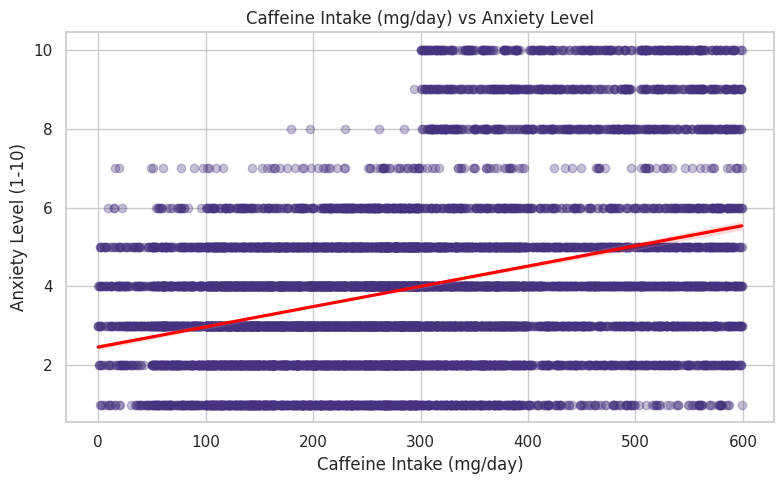

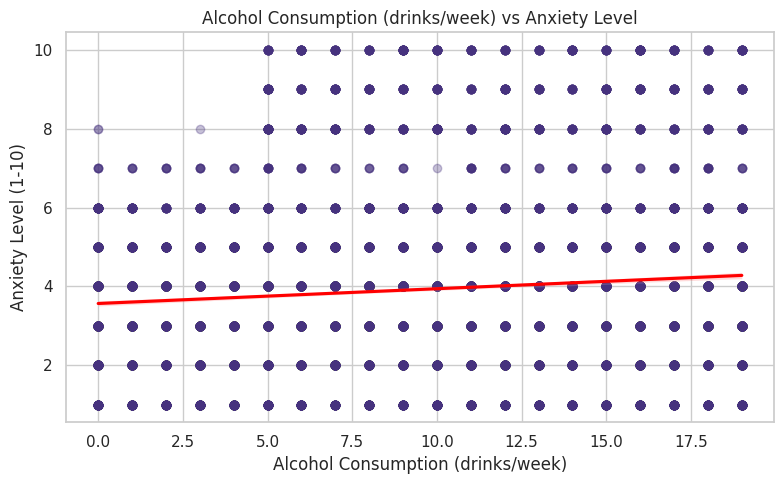

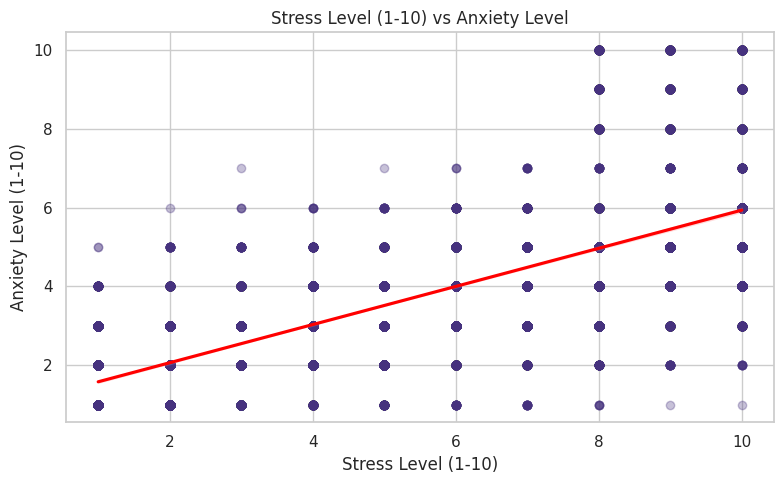

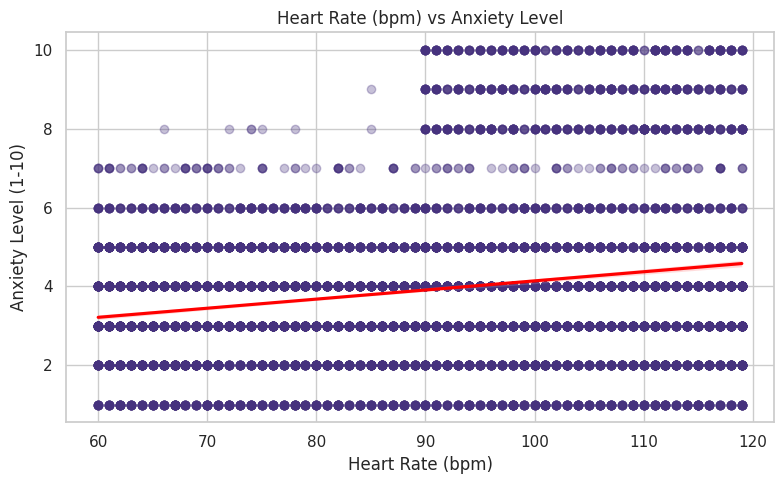

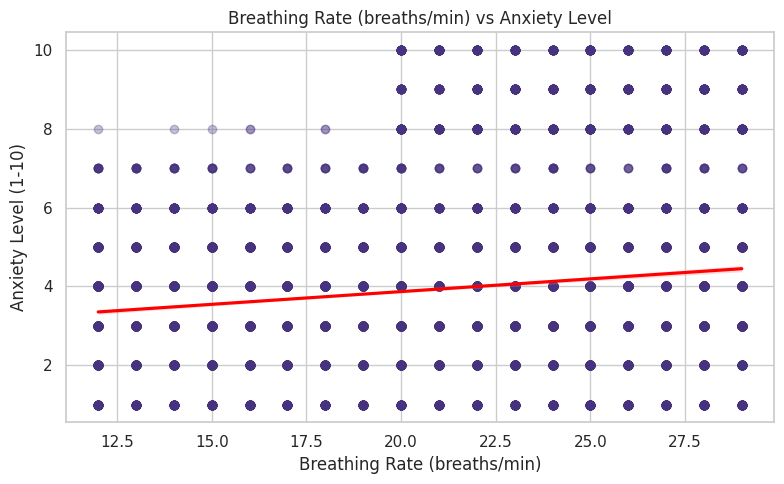

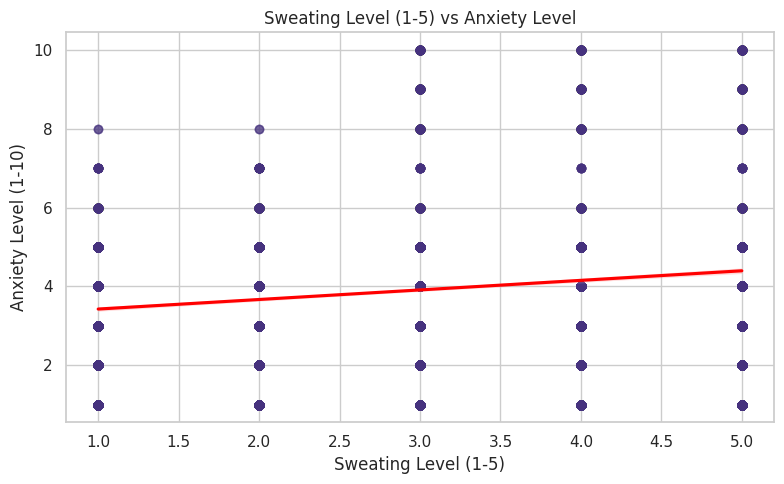

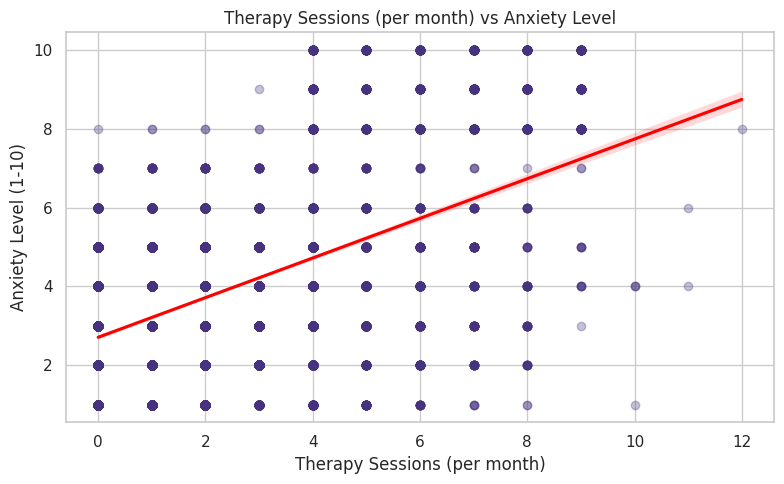

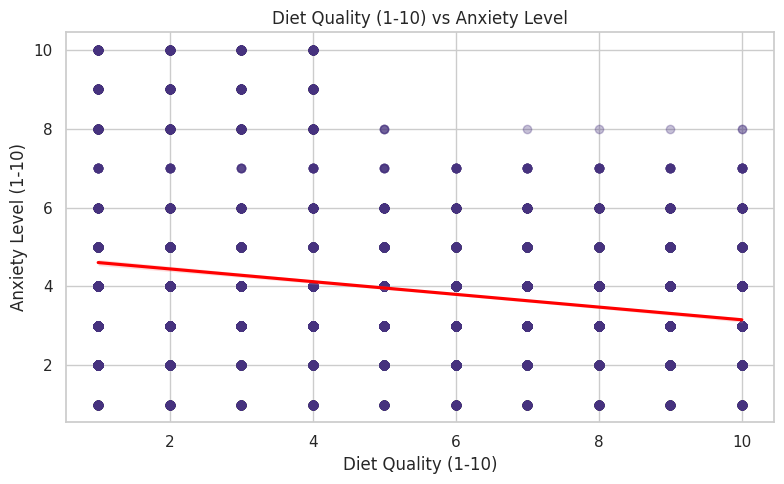

In [10]:
for col in numerical_cols:

    if col == TARGET:
        continue

    plt.figure(figsize=(8, 5))

    sns.regplot(
        data=df,
        x=col,
        y=TARGET,
        scatter_kws={"alpha": 0.3},
        line_kws={"color": "red"}
    )

    plt.title(f"{col} vs Anxiety Level")
    plt.tight_layout()
    plt.show()


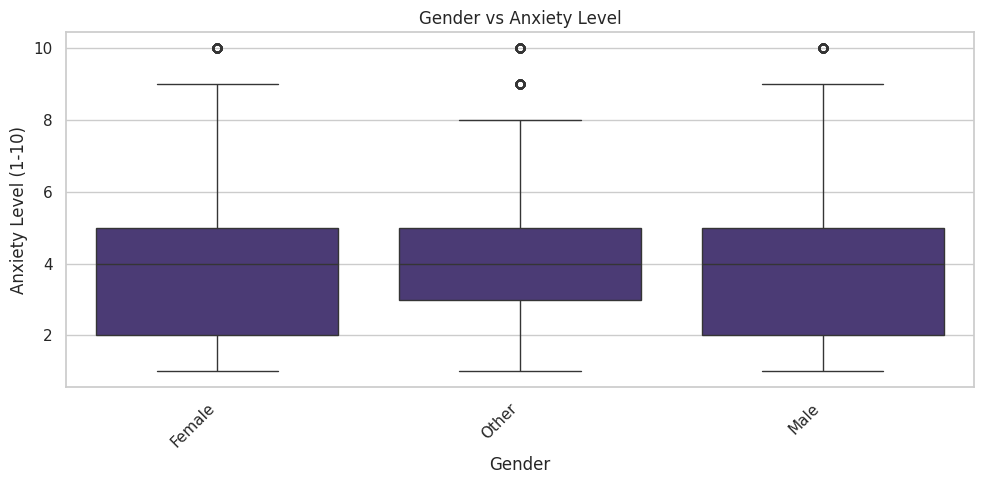


Mean Anxiety Level by Gender


,count,mean,median,std
Gender,,,,
Male,3657,3.933552,4.0,2.145861
Female,3730,3.931367,4.0,2.126240
Other,3613,3.923056,4.0,2.095360


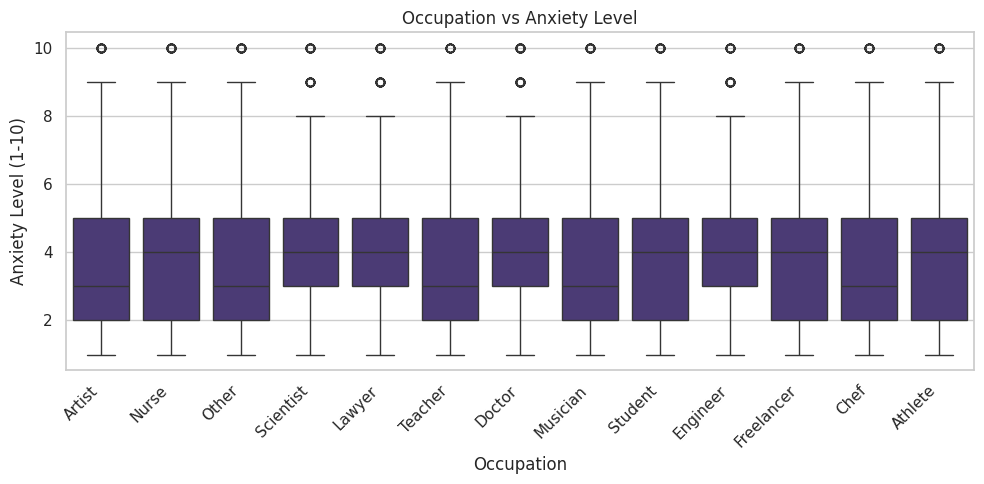


Mean Anxiety Level by Occupation


,count,mean,median,std
Occupation,,,,
Lawyer,809,4.206428,4.0,2.064710
Doctor,842,4.199525,4.0,2.174460
Engineer,833,4.138055,4.0,2.055458
Scientist,832,4.062500,4.0,2.087943
Freelancer,838,3.952267,4.0,2.152515
Student,878,3.883827,4.0,2.142620
Athlete,822,3.871046,4.0,2.146388
Nurse,861,3.854820,4.0,2.142280
Chef,858,3.840326,3.0,2.114882


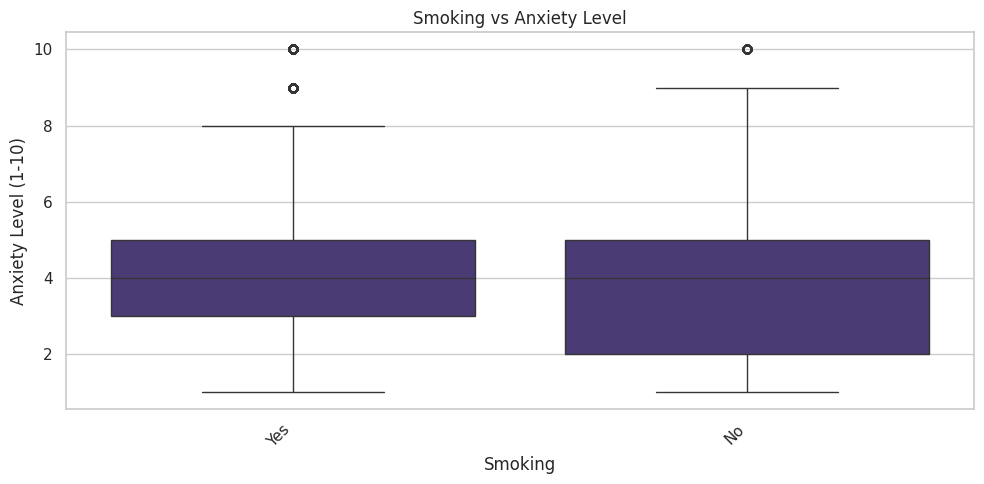


Mean Anxiety Level by Smoking


,count,mean,median,std
Smoking,,,,
Yes,5779,4.09448,4.0,2.270189
No,5221,3.74660,4.0,1.929890


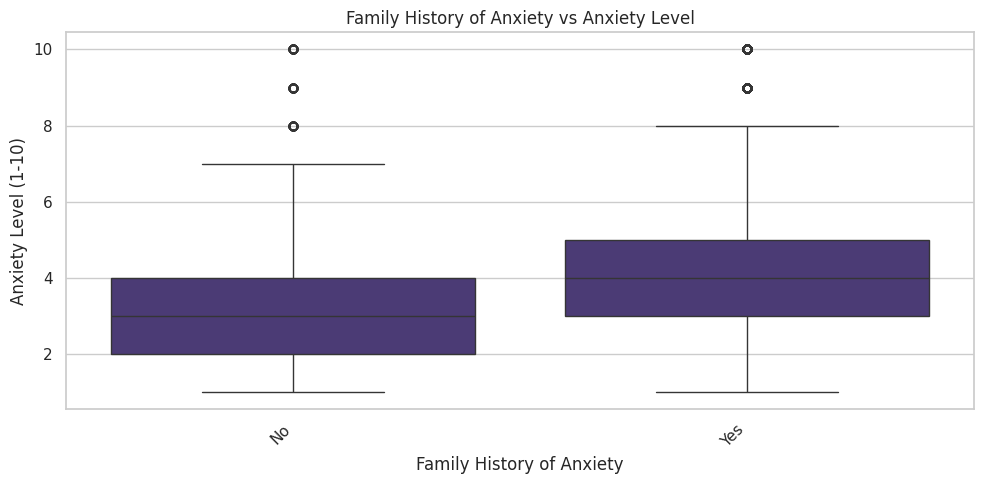


Mean Anxiety Level by Family History of Anxiety


,count,mean,median,std
Family History of Anxiety,,,,
Yes,5847,4.309731,4.0,2.294592
No,5153,3.497768,3.0,1.814699


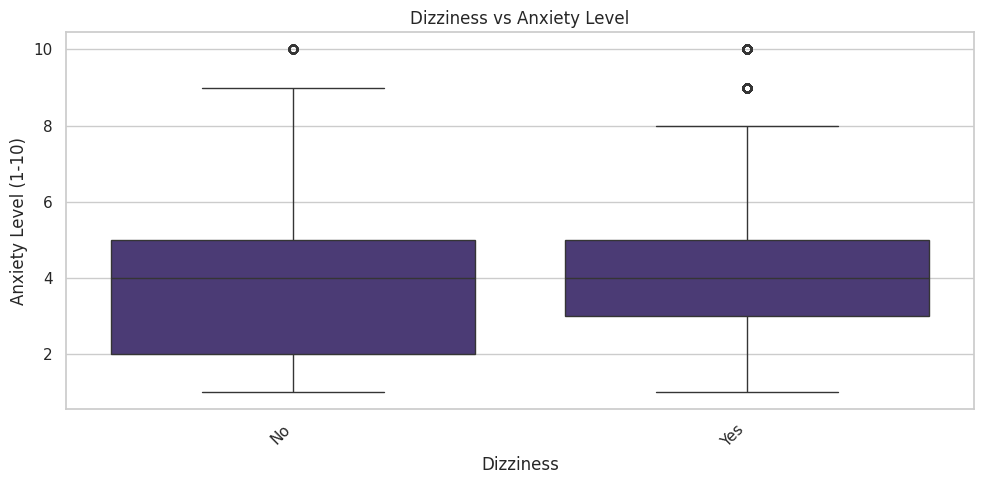


Mean Anxiety Level by Dizziness


,count,mean,median,std
Dizziness,,,,
Yes,5672,4.120769,4.0,2.294807
No,5328,3.725601,4.0,1.901400


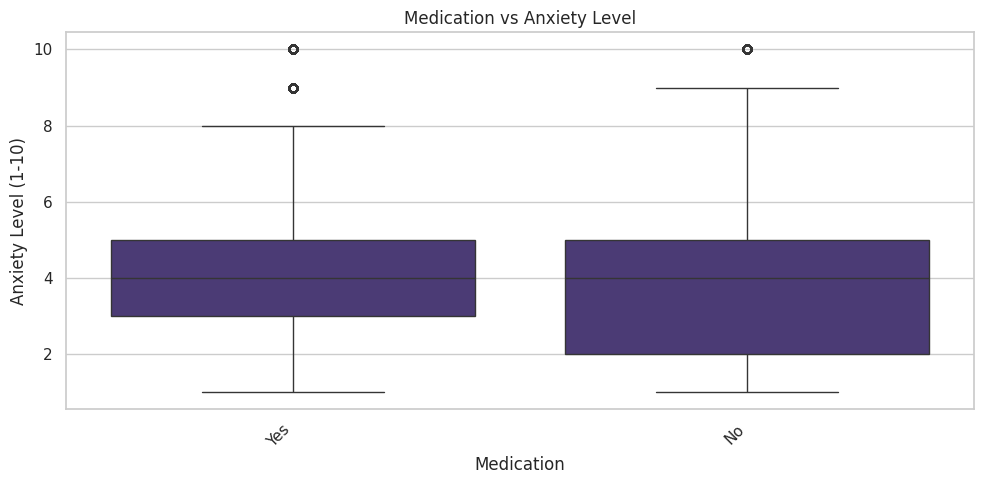


Mean Anxiety Level by Medication


,count,mean,median,std
Medication,,,,
Yes,5666,4.045711,4.0,2.193755
No,5334,3.805774,4.0,2.037101


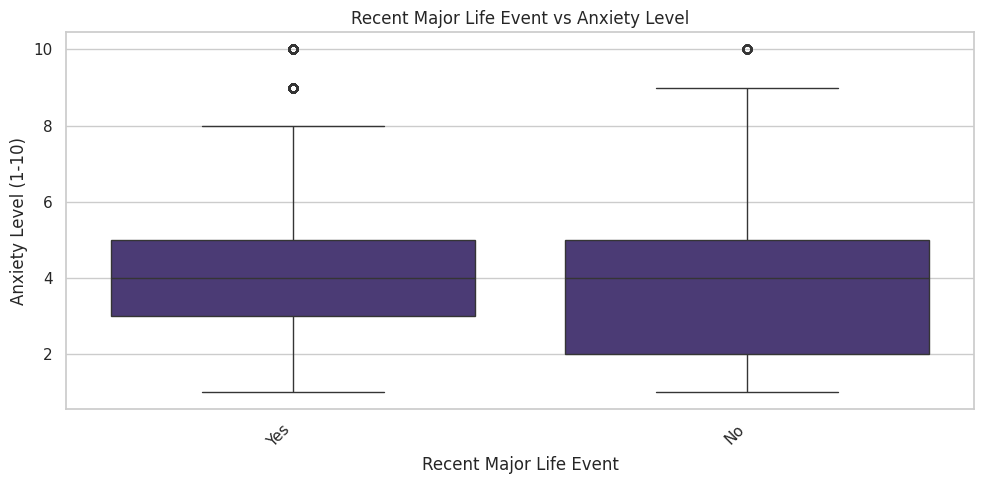


Mean Anxiety Level by Recent Major Life Event


,count,mean,median,std
Recent Major Life Event,,,,
Yes,5623,4.091766,4.0,2.280439
No,5377,3.759531,4.0,1.929374


In [11]:


for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x=col,
        y=TARGET
    )

    plt.title(f"{col} vs Anxiety Level")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print(f"\nMean Anxiety Level by {col}")
    display(
        df.groupby(col, observed=True)[TARGET]
        .agg(["count", "mean", "median", "std"])
        .sort_values("mean", ascending=False)
    )




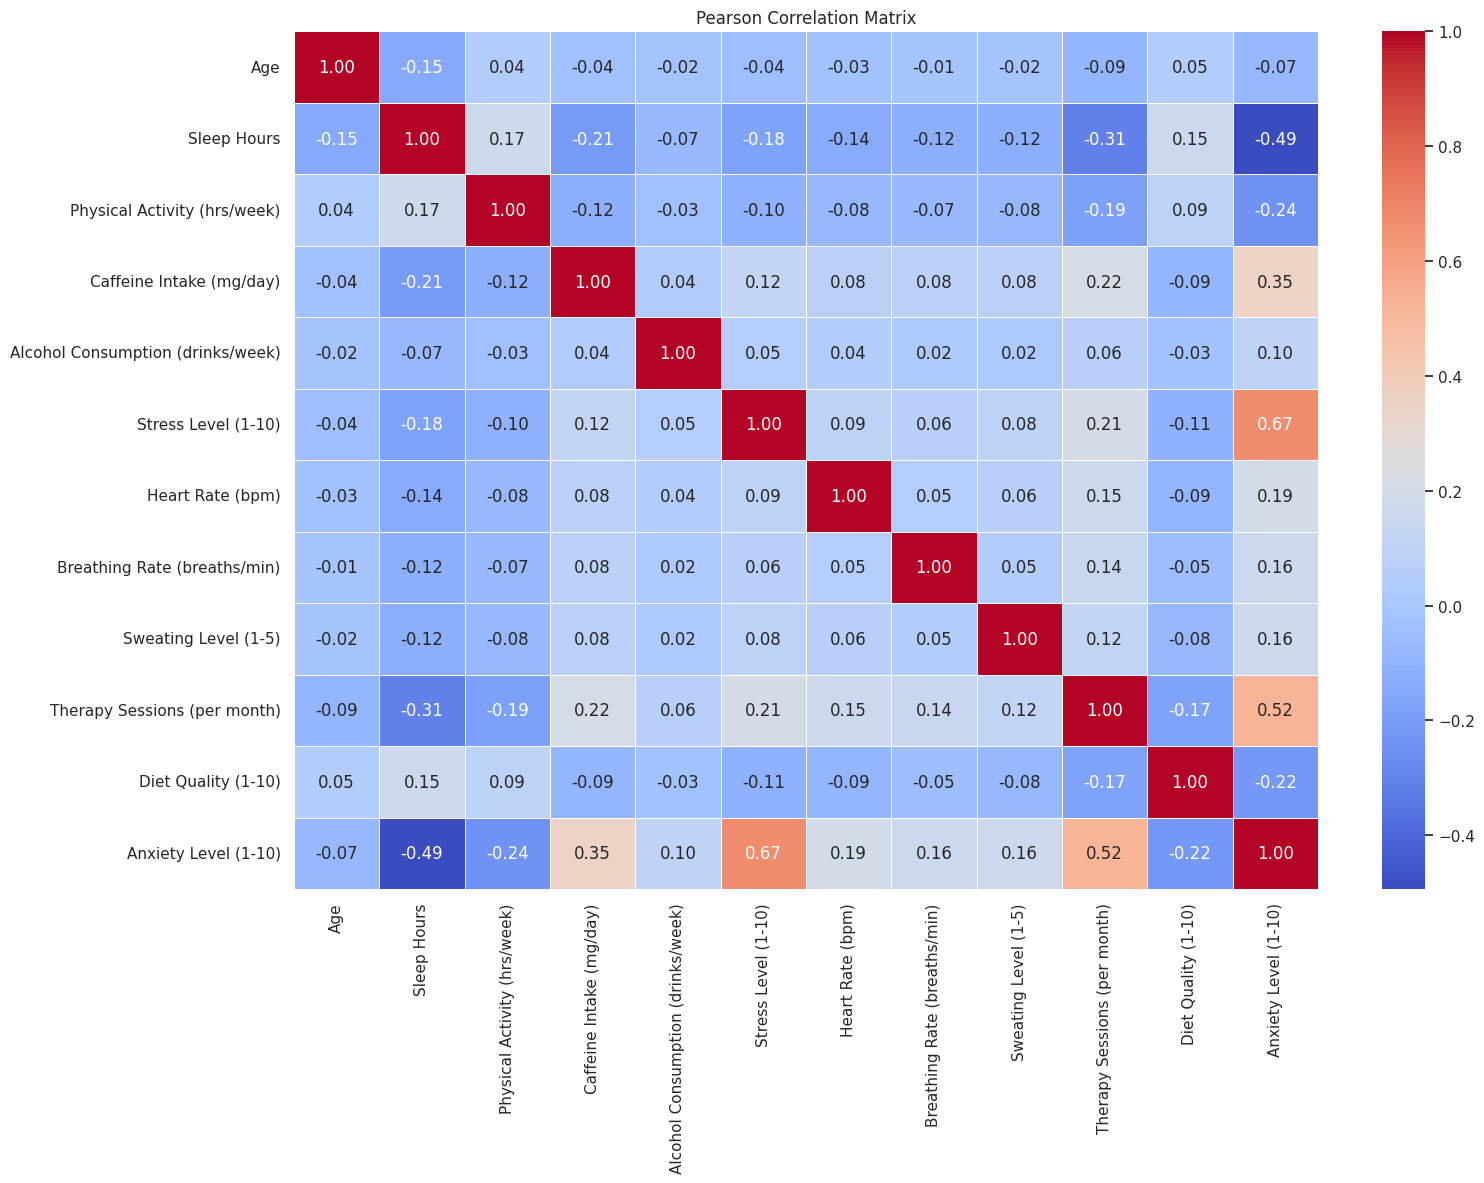

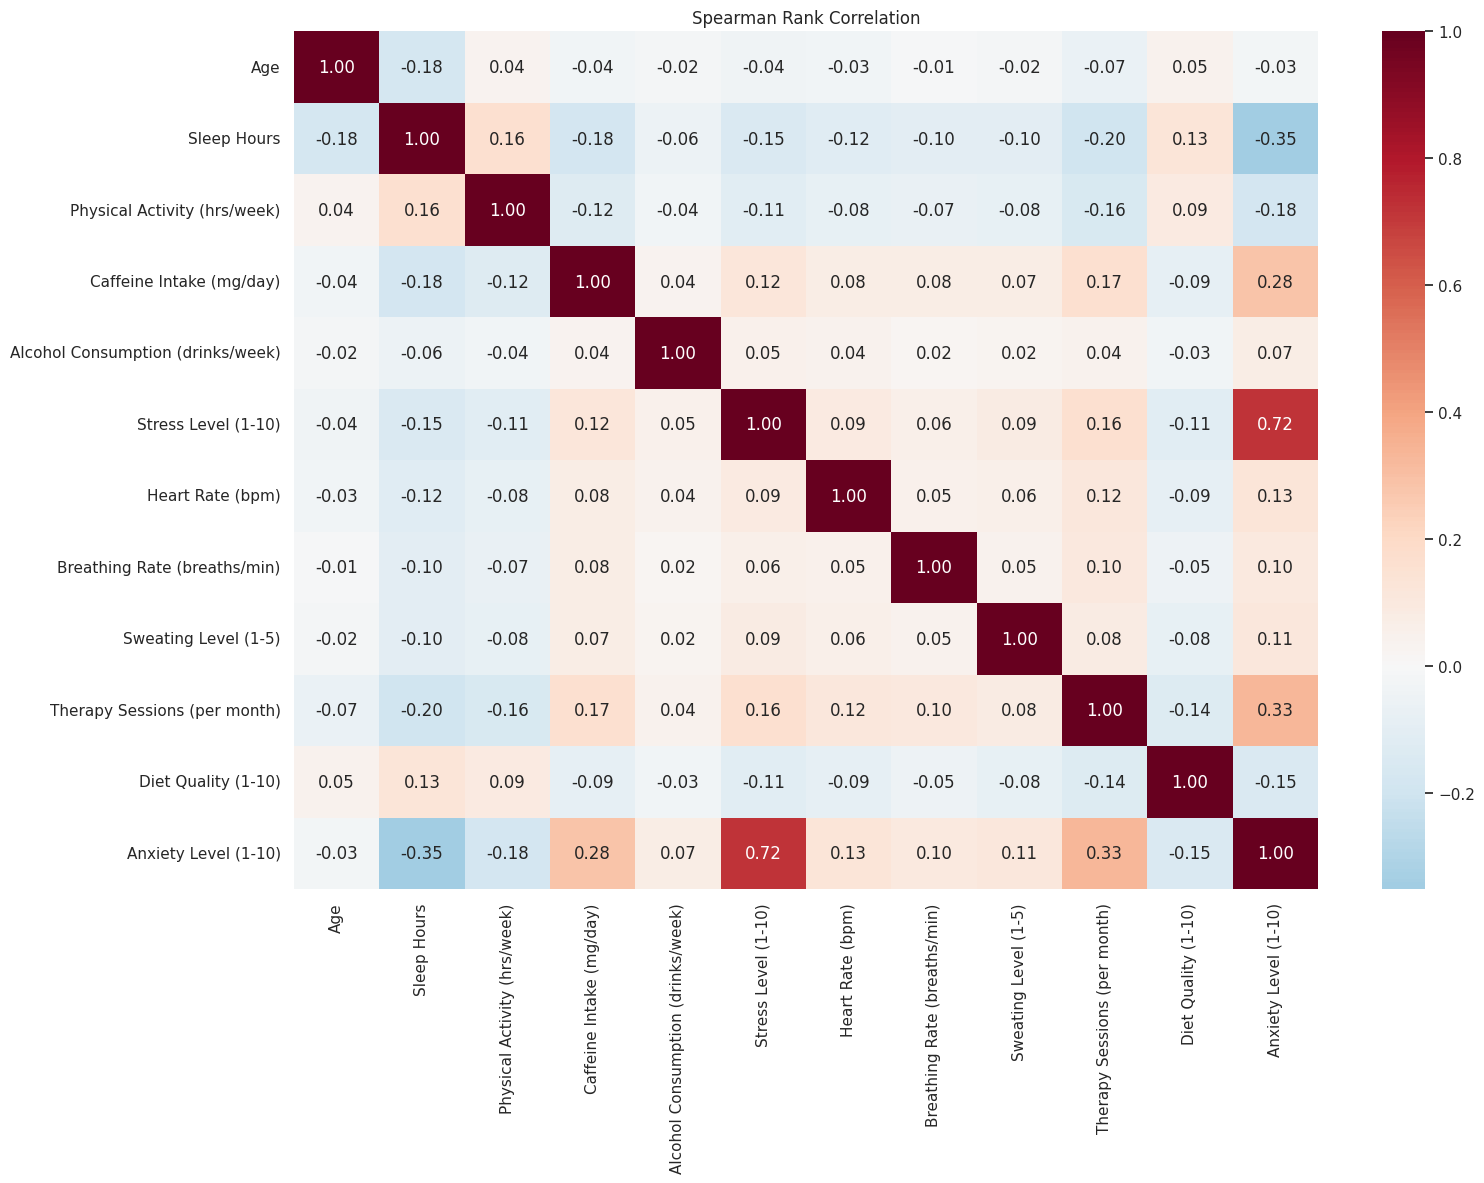


Correlation with Target:


,Correlation
Stress Level (1-10),0.667939
Therapy Sessions (per month),0.517606
Caffeine Intake (mg/day),0.350651
Heart Rate (bpm),0.188900
Sweating Level (1-5),0.160074
Breathing Rate (breaths/min),0.157048
Alcohol Consumption (drinks/week),0.100626
Age,-0.074316
Diet Quality (1-10),-0.220245
Physical Activity (hrs/week),-0.243187


In [12]:
# ============================================================
# 10. CORRELATION ANALYSIS
# ============================================================

correlation_matrix = df[numerical_cols].corr(method="pearson")

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()


# Spearman Correlation

spearman_corr = df[numerical_cols].corr(method="spearman")

plt.figure(figsize=(16, 12))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f"
)

plt.title("Spearman Rank Correlation")
plt.tight_layout()
plt.show()


print("\nCorrelation with Target:")

display(
    correlation_matrix[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
    .to_frame("Correlation")
)


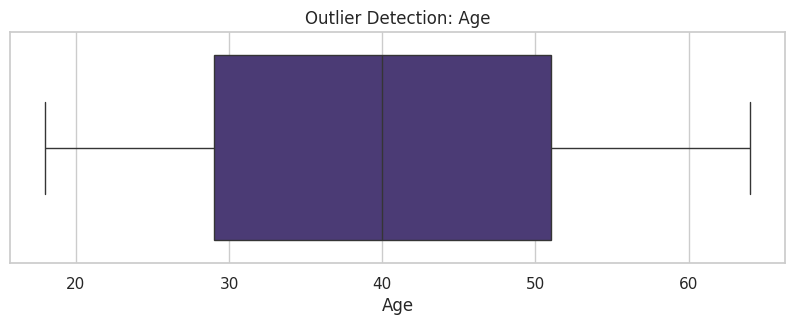

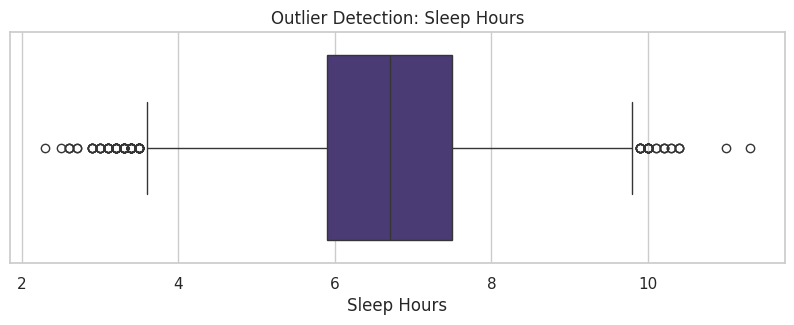

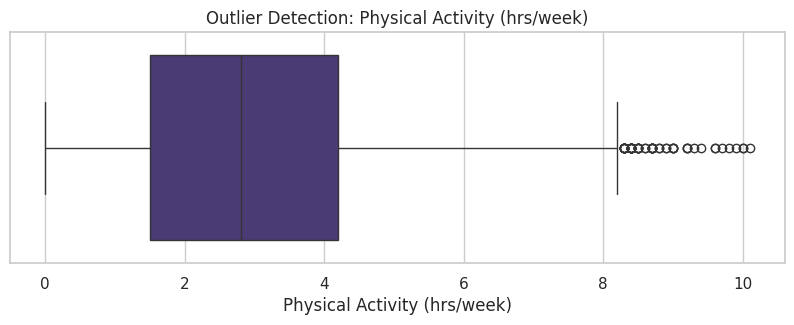

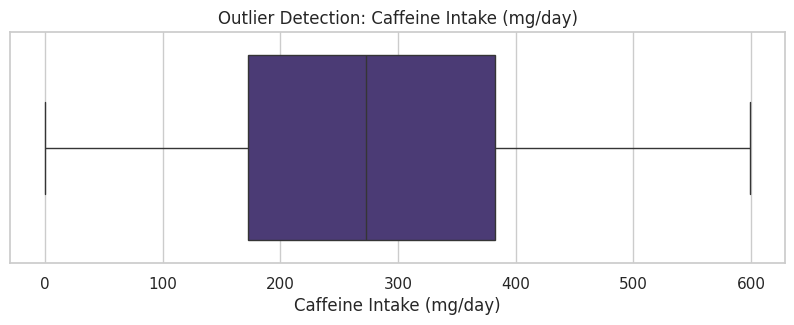

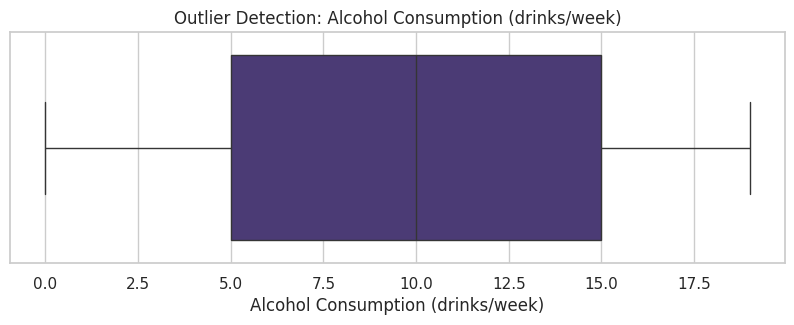

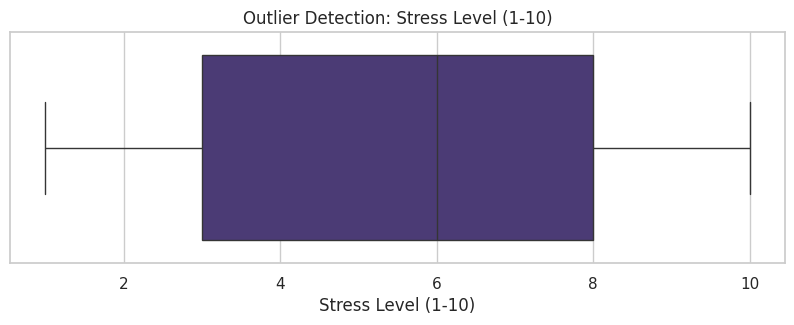

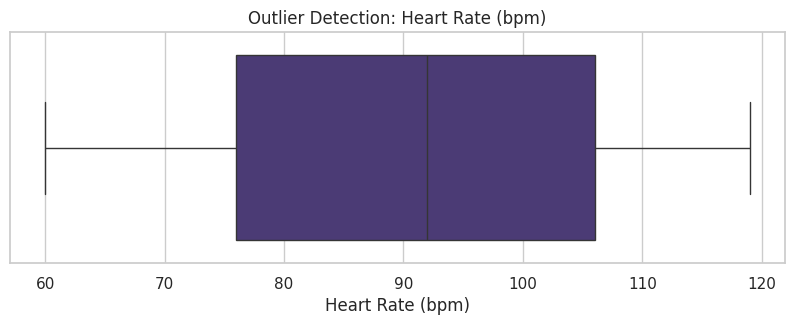

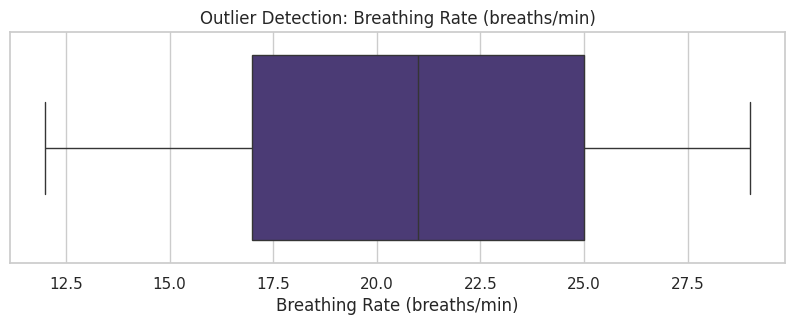

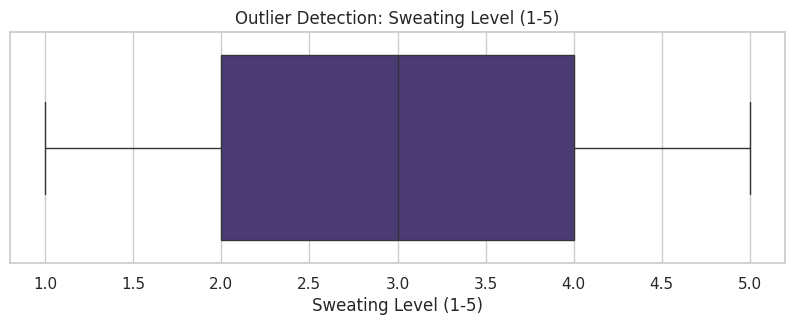

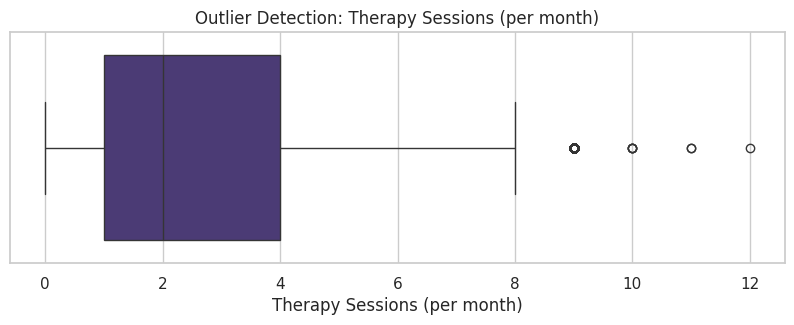

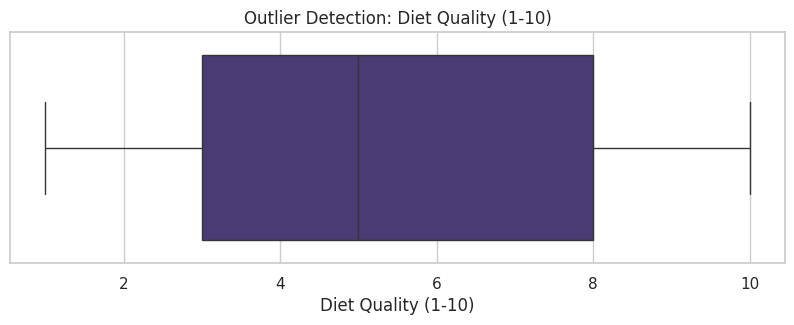

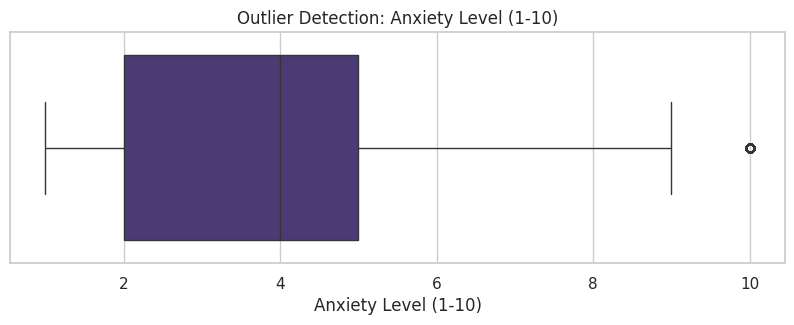

In [13]:
# ============================================================
# 11. OUTLIER DETECTION - BOXPLOTS
# ============================================================

for col in numerical_cols:

    plt.figure(figsize=(10, 3))

    sns.boxplot(x=df[col])

    plt.title(f"Outlier Detection: {col}")
    plt.show()

In [14]:
# ============================================================
# 12. IQR OUTLIER ANALYSIS
# ============================================================

outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)


,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Age,-4.00,84.00,0,0.000000
1,Sleep Hours,3.50,9.90,110,1.000000
2,Physical Activity (hrs/week),-2.55,8.25,56,0.509091
3,Caffeine Intake (mg/day),-143.00,697.00,0,0.000000
4,Alcohol Consumption (drinks/week),-10.00,30.00,0,0.000000
5,Stress Level (1-10),-4.50,15.50,0,0.000000
6,Heart Rate (bpm),31.00,151.00,0,0.000000
7,Breathing Rate (breaths/min),5.00,37.00,0,0.000000
8,Sweating Level (1-5),-1.00,7.00,0,0.000000
9,Therapy Sessions (per month),-3.50,8.50,178,1.618182


In [15]:
# ============================================================
# 13. STATISTICAL DISTRIBUTION ANALYSIS
# ============================================================

distribution_results = []

for col in numerical_cols:

    values = df[col].dropna()

    distribution_results.append({
        "Feature": col,
        "Mean": values.mean(),
        "Median": values.median(),
        "Mode": values.mode().iloc[0],
        "Variance": values.var(),
        "Std_Deviation": values.std(),
        "Skewness": stats.skew(values),
        "Kurtosis": stats.kurtosis(values)
    })

distribution_df = pd.DataFrame(distribution_results)

display(distribution_df)

,Feature,Mean,Median,Mode,Variance,Std_Deviation,Skewness,Kurtosis
0,Age,40.241727,40.0,30.0,175.195404,13.236140,0.097323,-1.126374
1,Sleep Hours,6.650691,6.7,6.7,1.506778,1.227509,-0.224442,-0.048092
2,Physical Activity (hrs/week),2.942136,2.8,1.9,3.340946,1.827825,0.506941,-0.215525
3,Caffeine Intake (mg/day),286.090000,273.0,294.0,20970.850341,144.813157,0.323897,-0.701673
4,Alcohol Consumption (drinks/week),9.701636,10.0,9.0,32.372831,5.689713,-0.023331,-1.159199
5,Stress Level (1-10),5.856364,6.0,10.0,8.568511,2.927202,-0.160850,-1.255706
6,Heart Rate (bpm),90.916000,92.0,112.0,300.180597,17.325721,-0.119188,-1.192627
7,Breathing Rate (breaths/min),20.957545,21.0,26.0,26.626709,5.160107,-0.141186,-1.171878
8,Sweating Level (1-5),3.080636,3.0,5.0,1.956857,1.398877,-0.073919,-1.263197
9,Therapy Sessions (per month),2.427818,2.0,1.0,4.765950,2.183106,1.034975,0.586111


In [16]:

# ============================================================
# 14. NORMALITY TEST
# ============================================================

normality_results = []

for col in numerical_cols:

    values = df[col].dropna()

    sample = values.sample(
        min(len(values), 5000),
        random_state=RANDOM_STATE
    )

    statistic, p_value = stats.normaltest(sample)

    normality_results.append({
        "Feature": col,
        "Statistic": statistic,
        "P_Value": p_value,
        "Normally_Distributed": p_value > 0.05
    })

display(pd.DataFrame(normality_results))

,Feature,Statistic,P_Value,Normally_Distributed
0,Age,2299.238317,0.000000e+00,False
1,Sleep Hours,32.088526,1.076627e-07,False
2,Physical Activity (hrs/week),210.602231,1.854841e-46,False
3,Caffeine Intake (mg/day),354.421267,1.092445e-77,False
4,Alcohol Consumption (drinks/week),3078.188096,0.000000e+00,False
5,Stress Level (1-10),7742.382921,0.000000e+00,False
6,Heart Rate (bpm),4061.620166,0.000000e+00,False
7,Breathing Rate (breaths/min),3335.977803,0.000000e+00,False
8,Sweating Level (1-5),7899.026603,0.000000e+00,False
9,Therapy Sessions (per month),660.707622,3.381916e-144,False


In [17]:
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.strip()

df.replace(["", " ", "NA", "N/A", "null", "None"], np.nan, inplace=True)

df.drop_duplicates(inplace=True)

df.drop(columns=constant_columns, errors="ignore", inplace=True)

print("Shape after cleaning:", df.shape)

Shape after cleaning: (11000, 19)


In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.impute import SimpleImputer

vif_data = df[numerical_cols].drop(columns=[TARGET])

vif_data = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(vif_data),
    columns=vif_data.columns
)

vif_results = pd.DataFrame()

vif_results["Feature"] = vif_data.columns

vif_results["VIF"] = [
    variance_inflation_factor(
        vif_data.values,
        i
    )
    for i in range(vif_data.shape[1])
]

display(vif_results.sort_values("VIF", ascending=False))

,Feature,VIF
1,Sleep Hours,1.238787
9,Therapy Sessions (per month),1.233869
3,Caffeine Intake (mg/day),1.088100
5,Stress Level (1-10),1.078829
2,Physical Activity (hrs/week),1.065961
10,Diet Quality (1-10),1.056722
0,Age,1.054387
6,Heart Rate (bpm),1.043640
7,Breathing Rate (breaths/min),1.031229
8,Sweating Level (1-5),1.031178


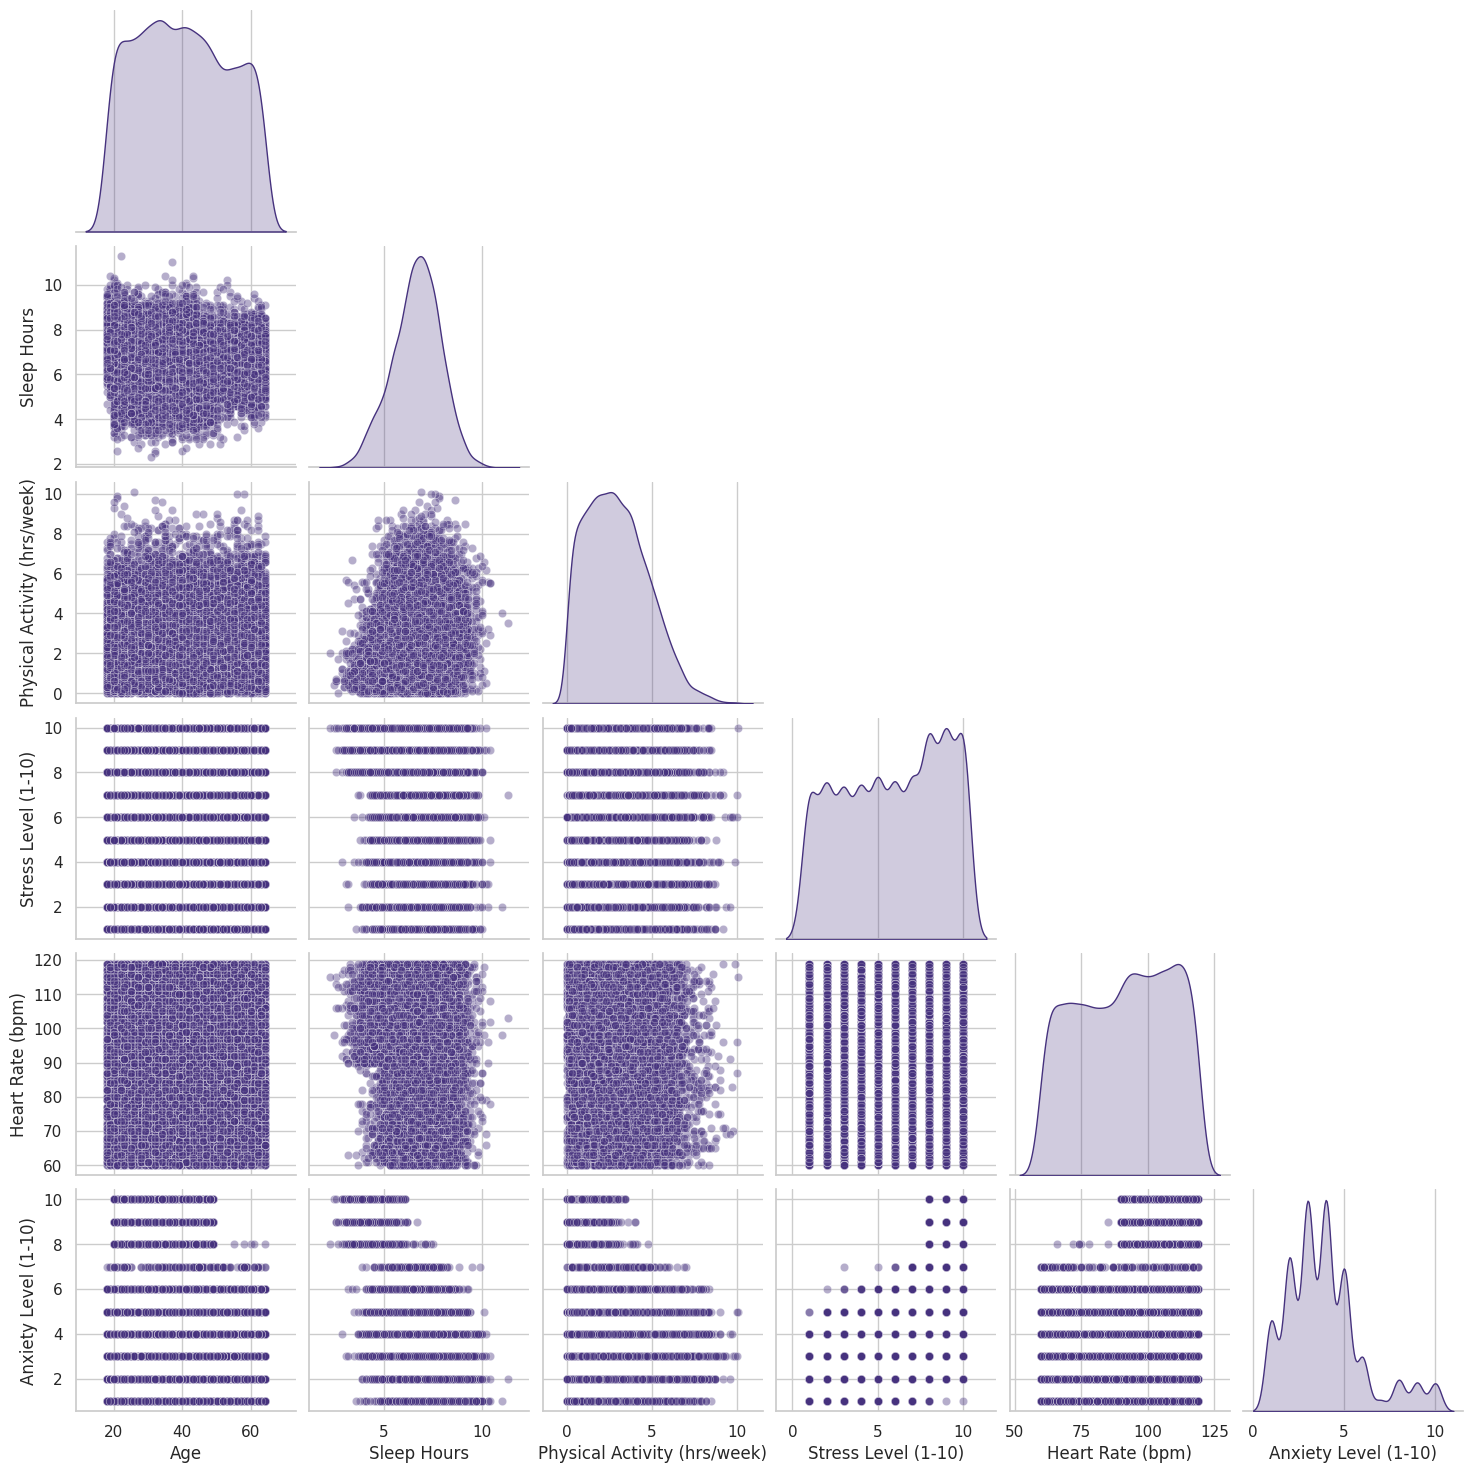

In [19]:
selected_features = [
    "Age",
    "Sleep Hours",
    "Physical Activity (hrs/week)",
    "Stress Level (1-10)",
    "Heart Rate (bpm)",
    "Anxiety Level (1-10)"
]

sns.pairplot(
    df[selected_features],
    corner=True,
    diag_kind="kde",
    plot_kws={"alpha": 0.4}
)

plt.show()

In [20]:

group_features = [
    "Gender",
    "Occupation",
    "Smoking",
    "Family History of Anxiety",
    "Dizziness",
    "Medication",
    "Recent Major Life Event"
]

for col in group_features:

    result = df.groupby(col, observed=True)[TARGET].agg(
        ["count", "mean", "median", "std"]
    )

    print(f"\nAnalysis by {col}")
    display(result.sort_values("mean", ascending=False))


Analysis by Gender


,count,mean,median,std
Gender,,,,
Male,3657,3.933552,4.0,2.145861
Female,3730,3.931367,4.0,2.126240
Other,3613,3.923056,4.0,2.095360



Analysis by Occupation


,count,mean,median,std
Occupation,,,,
Lawyer,809,4.206428,4.0,2.064710
Doctor,842,4.199525,4.0,2.174460
Engineer,833,4.138055,4.0,2.055458
Scientist,832,4.062500,4.0,2.087943
Freelancer,838,3.952267,4.0,2.152515
Student,878,3.883827,4.0,2.142620
Athlete,822,3.871046,4.0,2.146388
Nurse,861,3.854820,4.0,2.142280
Chef,858,3.840326,3.0,2.114882



Analysis by Smoking


,count,mean,median,std
Smoking,,,,
Yes,5779,4.09448,4.0,2.270189
No,5221,3.74660,4.0,1.929890


... (4 outputs left out)


Analysis by Medication


,count,mean,median,std
Medication,,,,
Yes,5666,4.045711,4.0,2.193755
No,5334,3.805774,4.0,2.037101



Analysis by Recent Major Life Event


,count,mean,median,std
Recent Major Life Event,,,,
Yes,5623,4.091766,4.0,2.280439
No,5377,3.759531,4.0,1.929374


In [21]:
df_processed = df.copy()

# Sleep Category

df_processed["Sleep Category"] = pd.cut(
    df_processed["Sleep Hours"],
    bins=[-np.inf, 5, 7, 9, np.inf],
    labels=["Very Low", "Low", "Optimal", "High"]
)

# Physical Activity Category

df_processed["Activity Category"] = pd.cut(
    df_processed["Physical Activity (hrs/week)"],
    bins=[-np.inf, 1, 3, 6, np.inf],
    labels=["Low", "Moderate", "High", "Very High"]
)

# Caffeine Category

df_processed["Caffeine Category"] = pd.cut(
    df_processed["Caffeine Intake (mg/day)"],
    bins=[-np.inf, 100, 200, 400, np.inf],
    labels=["Low", "Moderate", "High", "Very High"]
)

# Alcohol Category

df_processed["Alcohol Category"] = pd.cut(
    df_processed["Alcohol Consumption (drinks/week)"],
    bins=[-np.inf, 0, 3, 7, np.inf],
    labels=["None", "Low", "Moderate", "High"]
)

# Stress Category

df_processed["Stress Category"] = pd.cut(
    df_processed["Stress Level (1-10)"],
    bins=[0, 3, 6, 10],
    labels=["Low", "Moderate", "High"]
)

# Diet Category

df_processed["Diet Category"] = pd.cut(
    df_processed["Diet Quality (1-10)"],
    bins=[0, 3, 6, 10],
    labels=["Poor", "Moderate", "Good"]
)

# Physiological Indicator

df_processed["Heart Rate per Age"] = (
    df_processed["Heart Rate (bpm)"] /
    df_processed["Age"].replace(0, np.nan)
)

print("Feature Engineered Dataset:")
display(df_processed.head())


Feature Engineered Dataset:


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),...,Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10),Sleep Category,Activity Category,Caffeine Category,Alcohol Category,Stress Category,Diet Category,Heart Rate per Age
0,29,Female,Artist,6.0,2.7,181,10,Yes,No,10,...,Yes,7,5.0,Low,Moderate,Moderate,High,High,Good,3.931034
1,46,Other,Nurse,6.2,5.7,200,8,Yes,Yes,1,...,No,8,3.0,Low,High,Moderate,High,Low,Good,1.347826
2,64,Male,Other,5.0,3.7,117,4,No,Yes,1,...,Yes,1,1.0,Very Low,High,Moderate,Moderate,Low,Poor,1.421875
3,20,Female,Scientist,5.8,2.8,360,6,Yes,No,4,...,No,1,2.0,Low,Moderate,High,Moderate,Moderate,Poor,4.300000
4,49,Female,Other,8.2,2.3,247,4,Yes,No,1,...,No,3,1.0,Optimal,Moderate,High,Moderate,Low,Poor,2.000000


In [22]:
numeric_features = df_processed.drop(
    columns=[TARGET]
).select_dtypes(include=np.number).columns.tolist()

categorical_features = df_processed.drop(
    columns=[TARGET]
).select_dtypes(include=["object", "category"]).columns.tolist()

numeric_imputer = SimpleImputer(strategy="median")

categorical_imputer = SimpleImputer(strategy="most_frequent")

df_processed[numeric_features] = numeric_imputer.fit_transform(
    df_processed[numeric_features]
)

df_processed[categorical_features] = categorical_imputer.fit_transform(
    df_processed[categorical_features]
)

In [23]:
df_model = df_processed.copy()

for col in numeric_features:

    Q1 = df_model[col].quantile(0.25)
    Q3 = df_model[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_model[col] = df_model[col].clip(
        lower=lower,
        upper=upper
    )

In [24]:
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)


Feature Matrix Shape: (11000, 25)
Target Shape: (11000,)


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8800, 25)
Testing Data: (2200, 25)


In [26]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (8800, 60)
Processed Testing Shape: (2200, 60)


,Feature,Mutual_Information
5,numerical__Stress Level (1-10),0.365482
54,categorical__Stress Category_High,0.249153
55,categorical__Stress Category_Low,0.175647
1,numerical__Sleep Hours,0.175062
9,numerical__Therapy Sessions (per month),0.161825
41,categorical__Sleep Category_Very Low,0.156732
3,numerical__Caffeine Intake (mg/day),0.091623
10,numerical__Diet Quality (1-10),0.061804
2,numerical__Physical Activity (hrs/week),0.060022
6,numerical__Heart Rate (bpm),0.058663


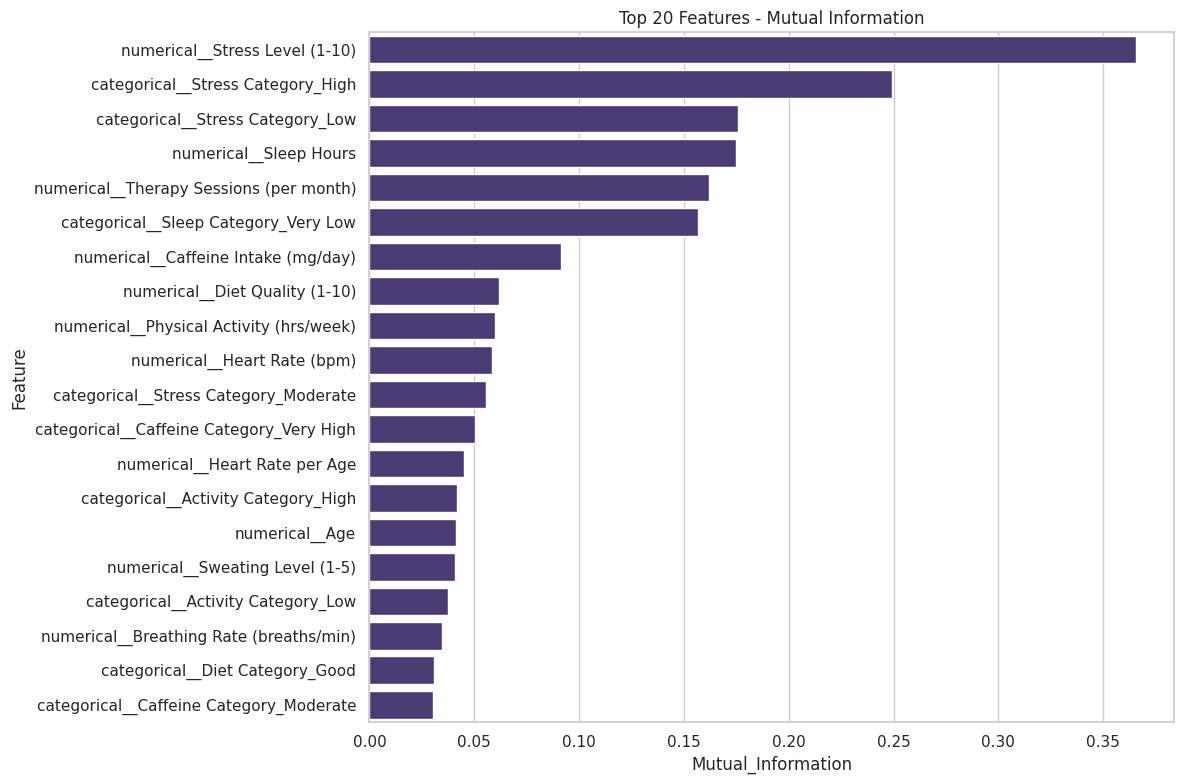

In [27]:

feature_selector = SelectKBest(
    score_func=mutual_info_regression,
    k="all"
)

feature_selector.fit(X_train_processed, y_train)

try:
    encoded_feature_names = preprocessor.get_feature_names_out()
except:
    encoded_feature_names = np.array([
        f"Feature_{i}"
        for i in range(X_train_processed.shape[1])
    ])

feature_importance = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Mutual_Information": feature_selector.scores_
})

feature_importance.sort_values(
    "Mutual_Information",
    ascending=False,
    inplace=True
)

display(feature_importance)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=feature_importance.head(20),
    x="Mutual_Information",
    y="Feature"
)

plt.title("Top 20 Features - Mutual Information")
plt.tight_layout()
plt.show()

In [28]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)

X_train_pca = pca.fit_transform(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

X_test_pca = pca.transform(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

print("Original Features:", X_train_processed.shape[1])
print("PCA Features:", X_train_pca.shape[1])

print(
    "Explained Variance Ratio:",
    pca.explained_variance_ratio_.sum()
)


Original Features: 60
PCA Features: 29
Explained Variance Ratio: 0.9526680906418219


In [29]:

df_processed.to_csv(
    "anxiety_dataset_cleaned.csv",
    index=False
)

df_model.to_csv(
    "anxiety_dataset_model_ready.csv",
    index=False
)

print("Preprocessing Completed Successfully.")

Preprocessing Completed Successfully.


# Exploratory Data Analysis

In [30]:
df

,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10)
0,29,Female,Artist,6.0,2.7,181,10,Yes,No,10,114,14,4,No,Yes,3,Yes,7,5.0
1,46,Other,Nurse,6.2,5.7,200,8,Yes,Yes,1,62,23,2,Yes,No,2,No,8,3.0
2,64,Male,Other,5.0,3.7,117,4,No,Yes,1,91,28,3,No,No,1,Yes,1,1.0
3,20,Female,Scientist,5.8,2.8,360,6,Yes,No,4,86,17,3,No,No,0,No,1,2.0
4,49,Female,Other,8.2,2.3,247,4,Yes,No,1,98,19,4,Yes,Yes,1,No,3,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10995,23,Female,Engineer,6.1,3.1,566,9,Yes,No,8,91,28,1,Yes,Yes,1,No,3,6.0
10996,50,Other,Teacher,6.6,3.6,64,17,Yes,No,7,95,17,3,No,No,2,No,7,3.0
10997,29,Male,Nurse,6.7,6.9,159,14,No,No,8,72,16,1,Yes,Yes,2,Yes,7,4.0
10998,53,Other,Artist,5.7,2.7,248,8,No,No,4,112,28,3,Yes,Yes,1,Yes,2,4.0


Target Variable distriution

In [31]:
print(df["Anxiety Level (1-10)"].value_counts().sort_index())

Anxiety Level (1-10)
1.0     1039
2.0     1756
3.0     2407
4.0     2416
5.0     1629
6.0      616
7.0      123
8.0      363
9.0      329
10.0     322
Name: count, dtype: int64


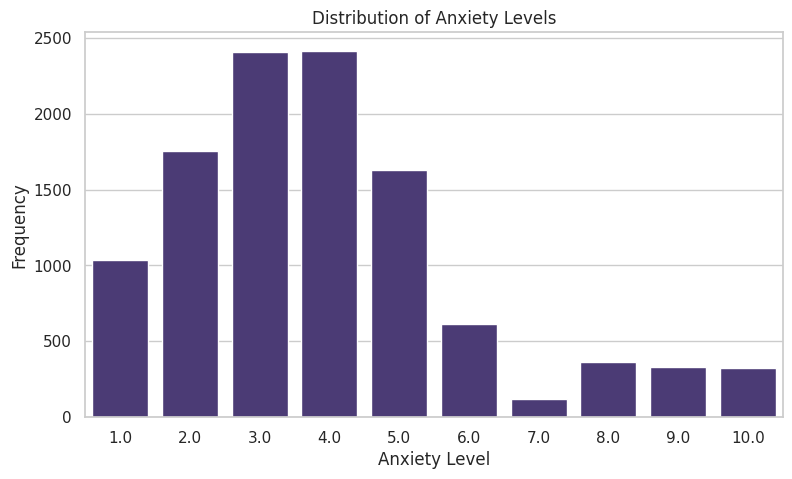

In [32]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Anxiety Level (1-10)"
)

plt.title("Distribution of Anxiety Levels")
plt.xlabel("Anxiety Level")
plt.ylabel("Frequency")
plt.show()

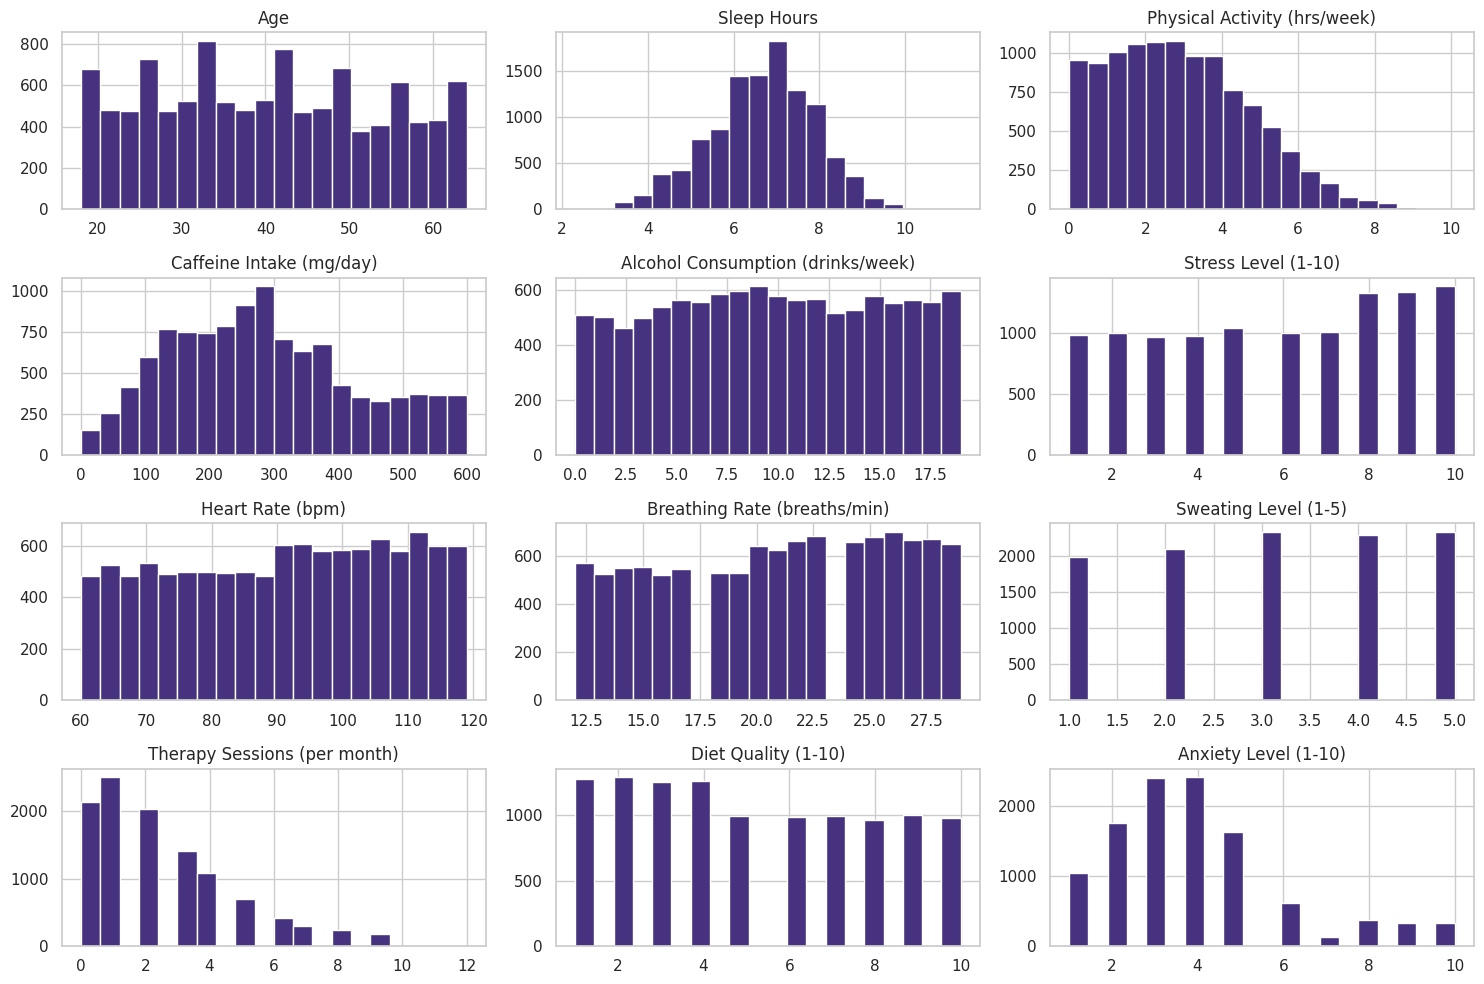

In [33]:
df.hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

# Train Models

In [34]:
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df["Anxiety Level (1-10)"].describe())

(11000, 19)
['Age', 'Gender', 'Occupation', 'Sleep Hours', 'Physical Activity (hrs/week)', 'Caffeine Intake (mg/day)', 'Alcohol Consumption (drinks/week)', 'Smoking', 'Family History of Anxiety', 'Stress Level (1-10)', 'Heart Rate (bpm)', 'Breathing Rate (breaths/min)', 'Sweating Level (1-5)', 'Dizziness', 'Medication', 'Therapy Sessions (per month)', 'Recent Major Life Event', 'Diet Quality (1-10)', 'Anxiety Level (1-10)']
   Age  Gender Occupation  Sleep Hours  Physical Activity (hrs/week)  \
0   29  Female     Artist          6.0                           2.7   
1   46   Other      Nurse          6.2                           5.7   
2   64    Male      Other          5.0                           3.7   
3   20  Female  Scientist          5.8                           2.8   
4   49  Female      Other          8.2                           2.3   

   Caffeine Intake (mg/day)  Alcohol Consumption (drinks/week) Smoking  \
0                       181                                 10   

In [35]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Define the five regression models
models = {
    "Linear Regression": LinearRegression(),

    "Elastic Net": ElasticNet(
        alpha=0.1,
        l1_ratio=0.5,
        max_iter=10000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "SVR": SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1
    )
}

# Store results and trained models
results = []
trained_models = {}

# Train and evaluate each model
for name, model in models.items():

    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    # Model training
    pipeline.fit(X_train, y_train)

    # Predictions
    predictions = pipeline.predict(X_test)

    # Evaluation metrics
    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    # Store results
    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

    print(f"{name} completed.")

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

Training Linear Regression...
Linear Regression completed.
Training Elastic Net...
Elastic Net completed.
Training Random Forest...
Random Forest completed.
Training Gradient Boosting...
Gradient Boosting completed.
Training SVR...
SVR completed.

MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting,0.8216,1.0379,1.0188,0.7760
1,Random Forest,0.8239,1.0418,1.0207,0.7752
2,Linear Regression,0.8783,1.2251,1.1069,0.7356
3,Elastic Net,0.8977,1.2841,1.1332,0.7229
4,SVR,0.9215,1.3199,1.1489,0.7151


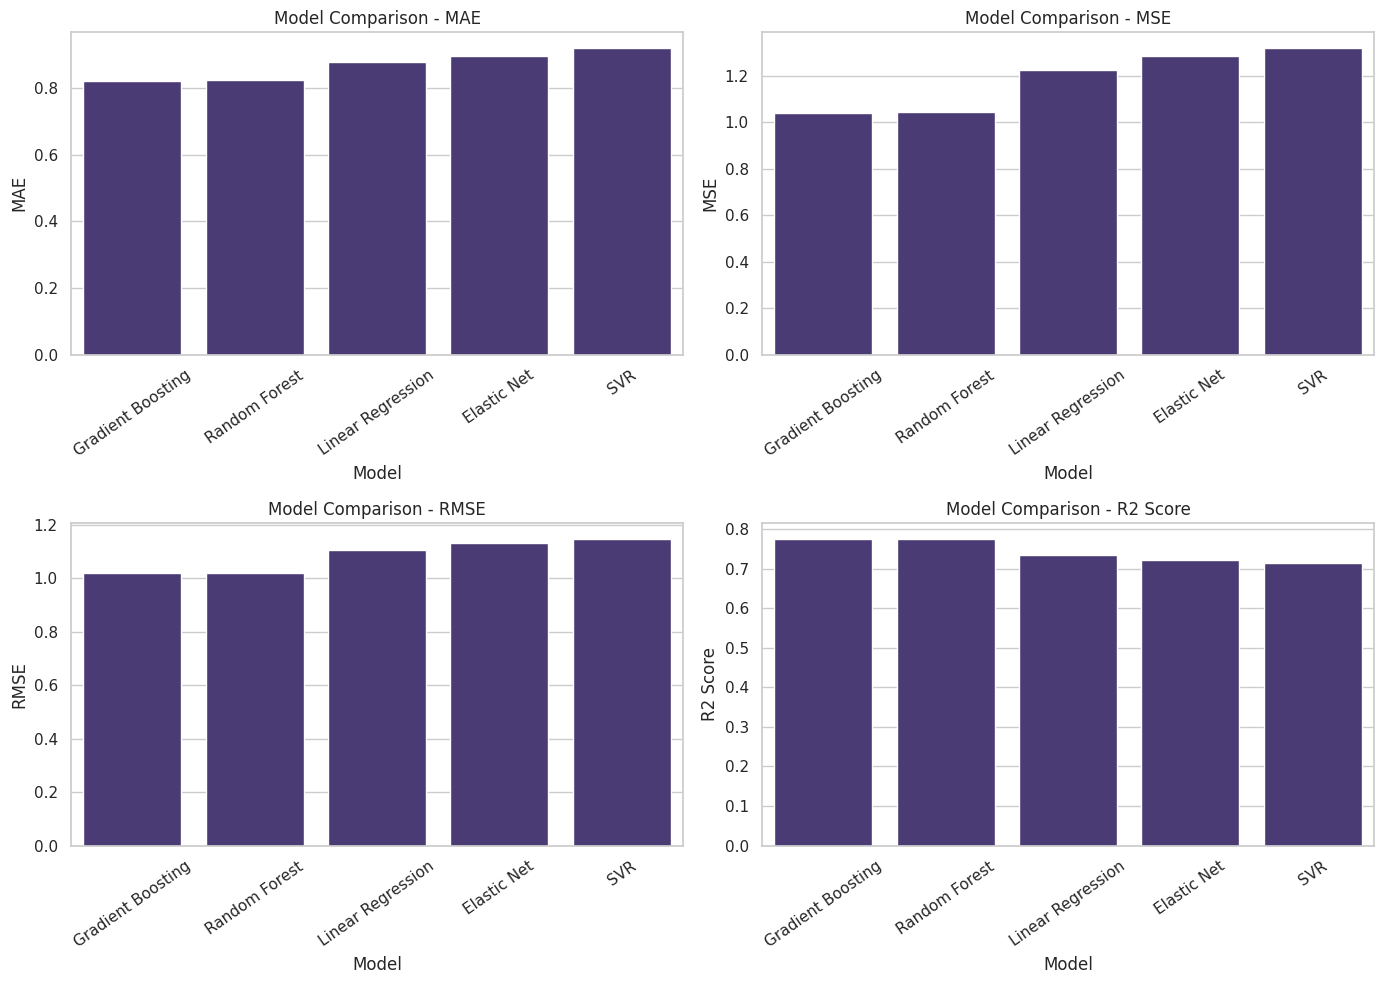

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["MAE", "MSE", "RMSE", "R2 Score"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, metric in zip(axes.flatten(), metrics):

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(f"Model Comparison - {metric}")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

In [37]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Define 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results = []

# Evaluate all five models
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_MAE"].mean(),
        "Mean MSE": -scores["test_MSE"].mean(),
        "Mean RMSE": -scores["test_RMSE"].mean(),
        "Mean R2": scores["test_R2"].mean(),
        "RMSE Std": scores["test_RMSE"].std()
    })

# Display results
cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean RMSE",
    ascending=True
).reset_index(drop=True)

display(cv_results_df.round(4))

,Model,Mean MAE,Mean MSE,Mean RMSE,Mean R2,RMSE Std
0,Gradient Boosting,0.8296,1.0651,1.0319,0.7615,0.0170
1,Random Forest,0.8343,1.0739,1.0361,0.7596,0.0193
2,Linear Regression,0.8878,1.2369,1.1120,0.7231,0.0193
3,Elastic Net,0.9062,1.2920,1.1366,0.7107,0.0144
4,SVR,0.9490,1.3927,1.1800,0.6881,0.0178


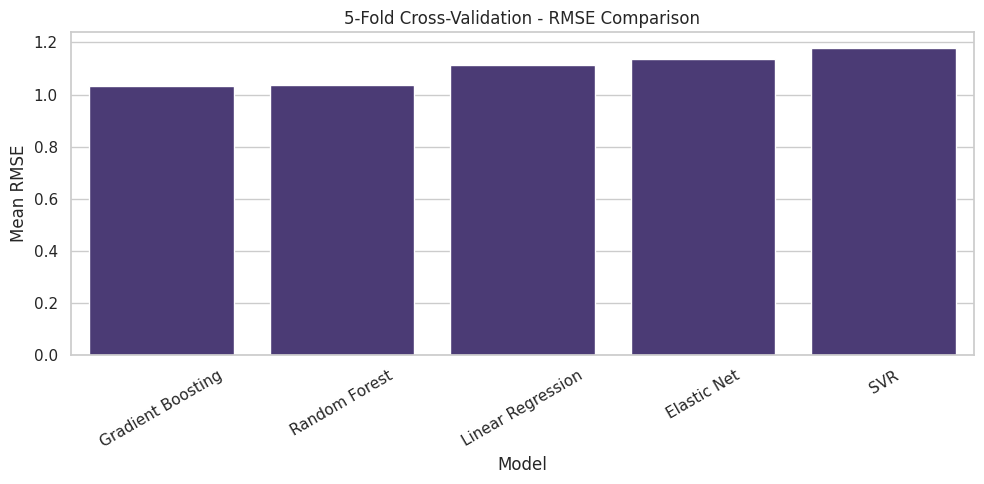

In [38]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="Mean RMSE"
)

plt.title("5-Fold Cross-Validation - RMSE Comparison")
plt.ylabel("Mean RMSE")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Hyperparameter Tuning

In [39]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Select the best model from cross-validation
best_model_name = cv_results_df.iloc[0]["Model"]

print("Best model before tuning:", best_model_name)

# Define parameter grids
param_grids = {

    "Linear Regression": {},

    "Elastic Net": {
        "model__alpha": [0.001, 0.01, 0.1, 1.0],
        "model__l1_ratio": [0.2, 0.5, 0.8]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3, 4]
    },

    "SVR": {
        "model__C": [1, 10, 50],
        "model__epsilon": [0.05, 0.1, 0.2],
        "model__gamma": ["scale", "auto"]
    }
}

# Create pipeline
tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(models[best_model_name]))
])

# Tune the selected model
if param_grids[best_model_name]:

    grid_search = GridSearchCV(
        estimator=tuning_pipeline,
        param_grid=param_grids[best_model_name],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    final_model = grid_search.best_estimator_

    print("\nBest Parameters:")
    print(grid_search.best_params_)

    print("\nBest Cross-Validation RMSE:")
    print(-grid_search.best_score_)

else:
    final_model = tuning_pipeline.fit(X_train, y_train)
    print("Linear Regression has no hyperparameters in this search.")

Best model before tuning: Gradient Boosting
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best Parameters:
{'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 200}

Best Cross-Validation RMSE:
1.0221603667433616


Model Evaluation

In [40]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict using the tuned model
final_predictions = final_model.predict(X_test)

# Calculate evaluation metrics
final_mae = mean_absolute_error(y_test, final_predictions)

final_mse = mean_squared_error(y_test, final_predictions)

final_rmse = np.sqrt(final_mse)

final_r2 = r2_score(y_test, final_predictions)

# Display results
print("FINAL MODEL: GRADIENT BOOSTING REGRESSOR")
print("----------------------------------------")
print("MAE:", round(final_mae, 4))
print("MSE:", round(final_mse, 4))
print("RMSE:", round(final_rmse, 4))
print("R2 Score:", round(final_r2, 4))

FINAL MODEL: GRADIENT BOOSTING REGRESSOR
----------------------------------------
MAE: 0.81
MSE: 1.0058
RMSE: 1.0029
R2 Score: 0.7829


Actual vs Predicted

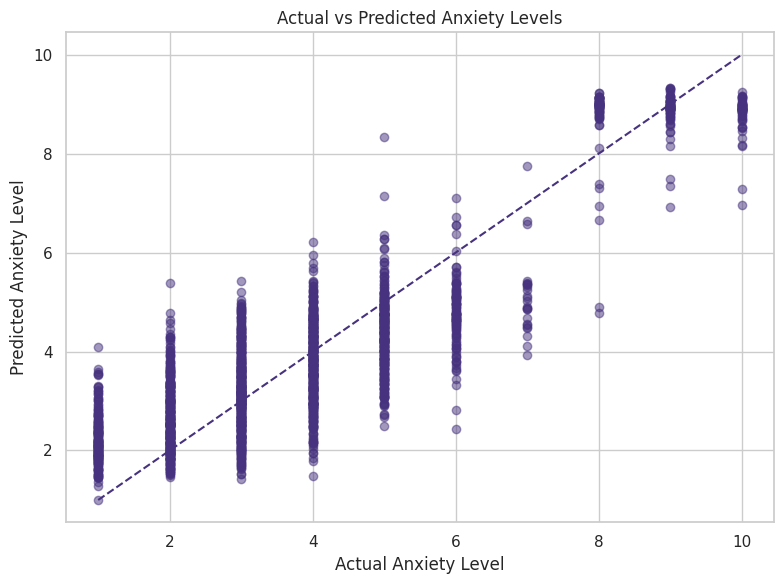

In [41]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.5
)

minimum = min(y_test.min(), final_predictions.min())
maximum = max(y_test.max(), final_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Anxiety Level")
plt.ylabel("Predicted Anxiety Level")
plt.title("Actual vs Predicted Anxiety Levels")

plt.tight_layout()
plt.show()

Residual Analysis

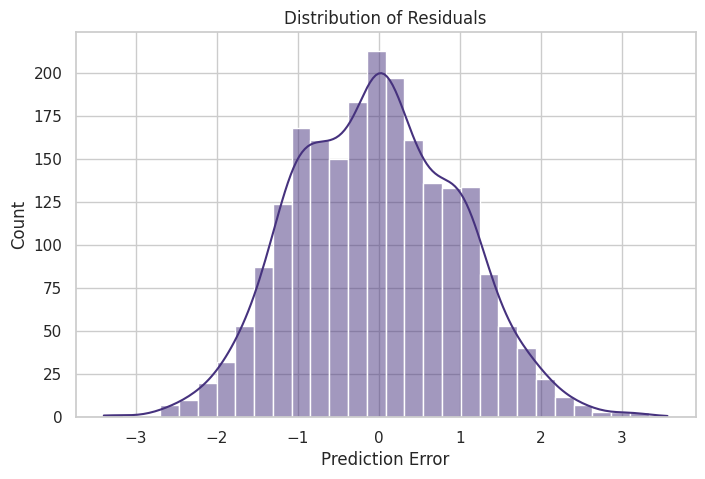

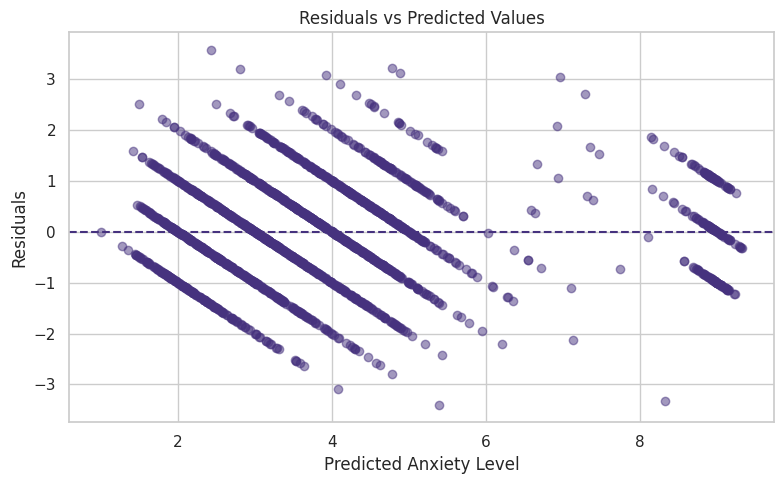

In [42]:
residuals = y_test - final_predictions

# Residual distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True,
    bins=30
)

plt.title("Distribution of Residuals")
plt.xlabel("Prediction Error")
plt.show()


# Residuals vs predicted values
plt.figure(figsize=(8, 5))

plt.scatter(
    final_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Anxiety Level")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.tight_layout()
plt.show()

# Classification

In [44]:
import numpy as np
import pandas as pd

# Create a separate dataframe for classification
df_classification = df_processed.copy()

# Convert numerical anxiety scores into four categories
bins = [0, 3, 6, 8, 10]
labels = ["Low", "Moderate", "High", "Very High"]

df_classification["Anxiety Category"] = pd.cut(
    df_classification["Anxiety Level (1-10)"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Check class distribution
print(df_classification["Anxiety Category"].value_counts())
print(df_classification["Anxiety Category"].value_counts(normalize=True) * 100)

Anxiety Category
Low          5202
Moderate     4661
Very High     651
High          486
Name: count, dtype: int64
Anxiety Category
Low          47.290909
Moderate     42.372727
Very High     5.918182
High          4.418182
Name: proportion, dtype: float64


In [45]:
X = df_classification.drop(
    columns=["Anxiety Level (1-10)", "Anxiety Category"]
)

y = df_classification["Anxiety Category"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (11000, 25)
Target shape: (11000,)


In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training records: 8800
Testing records: 2200

Training class distribution:
Anxiety Category
Low          4161
Moderate     3729
Very High     521
High          389
Name: count, dtype: int64

Testing class distribution:
Anxiety Category
Low          1041
Moderate      932
Very High     130
High           97
Name: count, dtype: int64


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 12
Categorical features: 13


Baseline Model

In [48]:
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

Improved Model

In [49]:
from sklearn.ensemble import RandomForestClassifier

improved_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

improved_model.fit(X_train, y_train)

improved_predictions = improved_model.predict(X_test)

Evaluate both models

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

results = []

for name, predictions in [
    ("Logistic Regression", baseline_predictions),
    ("Random Forest", improved_predictions)
]:

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 Score (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        )
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4))

                 Model  Accuracy  Precision (Macro)  Recall (Macro)  \
0  Logistic Regression    0.7091             0.5829          0.6153   
1        Random Forest    0.7518             0.6843          0.6389   

   F1 Score (Macro)  Balanced Accuracy  
0            0.5947             0.6153  
1            0.6023             0.6389  


Classification Report

In [52]:
print("LOGISTIC REGRESSION – CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    baseline_predictions,
    labels=labels,
    zero_division=0
))

print("\nRANDOM FOREST – CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    improved_predictions,
    labels=labels,
    zero_division=0
))

LOGISTIC REGRESSION – CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.80      0.78      0.79      1041
    Moderate       0.72      0.67      0.70       932
        High       0.17      0.28      0.21        97
   Very High       0.65      0.73      0.69       130

    accuracy                           0.71      2200
   macro avg       0.58      0.62      0.59      2200
weighted avg       0.73      0.71      0.72      2200


RANDOM FOREST – CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.78      0.79      0.79      1041
    Moderate       0.74      0.75      0.74       932
        High       0.56      0.05      0.09        97
   Very High       0.66      0.96      0.78       130

    accuracy                           0.75      2200
   macro avg       0.68      0.64      0.60      2200
weighted avg       0.75      0.75      0.74      2200



Confusion Matrix

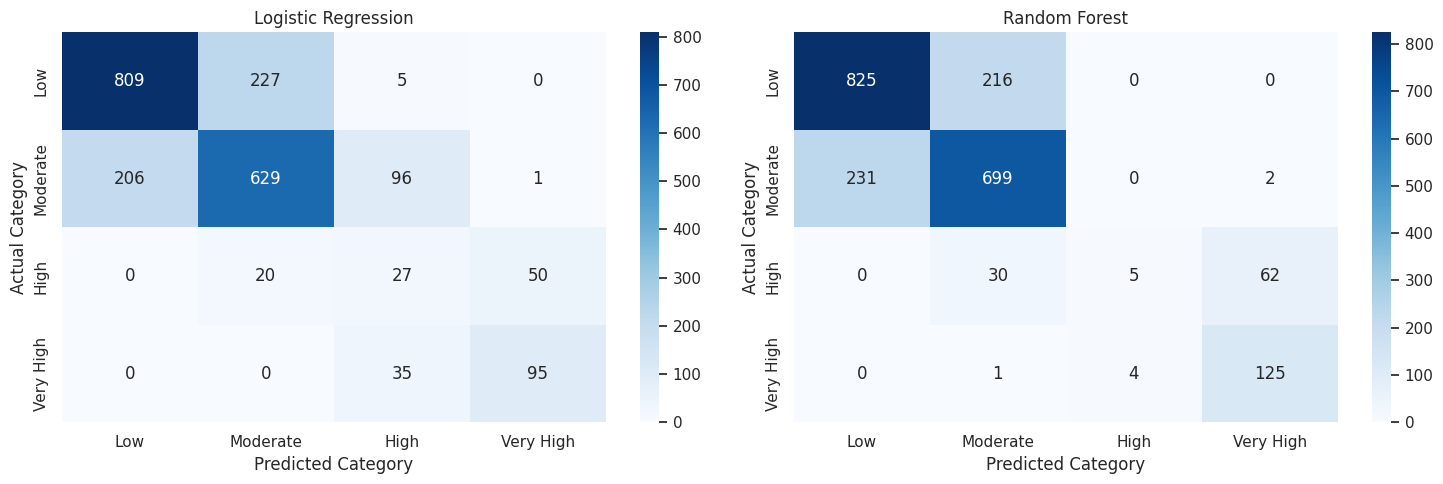

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, name, predictions in [
    (axes[0], "Logistic Regression", baseline_predictions),
    (axes[1], "Random Forest", improved_predictions)
]:

    cm = confusion_matrix(y_test, predictions, labels=labels)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Category")
    ax.set_ylabel("Actual Category")

plt.tight_layout()
plt.show()

Statistical Comparison

In [54]:
from scipy.stats import binomtest

# Identify correct and incorrect predictions
baseline_correct = (
    np.asarray(baseline_predictions) == np.asarray(y_test)
)

improved_correct = (
    np.asarray(improved_predictions) == np.asarray(y_test)
)

# Discordant pairs
b = np.sum(baseline_correct & ~improved_correct)
c = np.sum(~baseline_correct & improved_correct)

# Exact McNemar test
if b + c == 0:
    p_value = 1.0
else:
    test_result = binomtest(
        min(b, c),
        n=b + c,
        p=0.5,
        alternative="two-sided"
    )
    p_value = test_result.pvalue

print("Baseline correct, improved incorrect:", b)
print("Baseline incorrect, improved correct:", c)
print("McNemar exact p-value:", p_value)

if p_value < 0.05:
    print("The difference in classification accuracy is statistically significant.")
else:
    print("There is insufficient evidence of a significant difference in accuracy.")

Baseline correct, improved incorrect: 85
Baseline incorrect, improved correct: 179
McNemar exact p-value: 7.299435350362888e-09
The difference in classification accuracy is statistically significant.


Macro F1 score

In [55]:
from sklearn.metrics import f1_score

y_true = np.asarray(y_test)
pred_base = np.asarray(baseline_predictions)
pred_improved = np.asarray(improved_predictions)

# Observed difference
observed_difference = (
    f1_score(y_true, pred_improved, labels=labels,
             average="macro", zero_division=0)
    -
    f1_score(y_true, pred_base, labels=labels,
             average="macro", zero_division=0)
)

# Paired bootstrap
rng = np.random.default_rng(42)

n = len(y_true)
bootstrap_differences = []

for _ in range(5000):

    indices = rng.choice(n, size=n, replace=True)

    base_f1 = f1_score(
        y_true[indices],
        pred_base[indices],
        labels=labels,
        average="macro",
        zero_division=0
    )

    improved_f1 = f1_score(
        y_true[indices],
        pred_improved[indices],
        labels=labels,
        average="macro",
        zero_division=0
    )

    bootstrap_differences.append(improved_f1 - base_f1)

lower, upper = np.percentile(
    bootstrap_differences, [2.5, 97.5]
)

print("Observed Macro F1 difference:", observed_difference)
print("95% Bootstrap Confidence Interval:", (lower, upper))

if lower > 0:
    print("The improved candidate has a higher macro F1 with a confidence interval above zero.")
elif upper < 0:
    print("The baseline has a higher macro F1 with a confidence interval below zero.")
else:
    print("The confidence interval includes zero; the observed macro F1 difference is uncertain.")

Observed Macro F1 difference: 0.007606605715113179
95% Bootstrap Confidence Interval: (np.float64(-0.021780490909367067), np.float64(0.037871634985411025))
The confidence interval includes zero; the observed macro F1 difference is uncertain.


Comparison

In [56]:
print("FINAL MODEL COMPARISON")
print(comparison_df.round(4).to_string(index=False))

print("\nMacro F1 Difference (Random Forest - Logistic Regression):",
      round(observed_difference, 4))

print("95% Confidence Interval:", (round(lower, 4), round(upper, 4)))
print("McNemar p-value:", round(p_value, 6))

FINAL MODEL COMPARISON
              Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 Score (Macro)  Balanced Accuracy
Logistic Regression    0.7091             0.5829          0.6153            0.5947             0.6153
      Random Forest    0.7518             0.6843          0.6389            0.6023             0.6389

Macro F1 Difference (Random Forest - Logistic Regression): 0.0076
95% Confidence Interval: (np.float64(-0.0218), np.float64(0.0379))
McNemar p-value: 0.0


frontend setup

In [57]:
import pickle

with open("anxiety_gb_pipeline.pkl", "wb") as f:
    pickle.dump(final_model, f)

print("Model saved successfully!")

Model saved successfully!


In [58]:
from google.colab import files

files.download("anxiety_gb_pipeline.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

uploaded = files.upload()

creating project folder

In [59]:
import os

os.makedirs("/content/anxiety_streamlit_app", exist_ok=True)

%cd /content/anxiety_streamlit_app

/content/anxiety_streamlit_app


Create app.py

In [60]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import pickle
from pathlib import Path
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Anxiety Level Prediction",
    page_icon="🧠",
    layout="wide"
)

st.title("🧠 Anxiety Level Prediction")
st.write(
    "Enter the details below to estimate the anxiety level "
    "using the trained Gradient Boosting Regression model."
)

BASE_DIR = Path(__file__).parent
MODEL_PATH = BASE_DIR / "anxiety_gb_pipeline.pkl"
DATA_PATH = BASE_DIR / "enhanced_anxiety_dataset.csv"


# --------------------------------------------------
# 2. LOAD TRAINED MODEL AND DATASET
# --------------------------------------------------

@st.cache_resource
def load_model():
    with open(MODEL_PATH, "rb") as file:
        model = pickle.load(file)
    return model


@st.cache_data
def load_dataset():
    return pd.read_csv(DATA_PATH)


try:
    final_model = load_model()
    training_data = load_dataset()

except FileNotFoundError as error:
    st.error(f"Required file not found: {error}")
    st.info(
        "Make sure anxiety_gb_pipeline.pkl and "
        "enhanced_anxiety_dataset.csv are in the same folder as app.py."
    )
    st.stop()


# --------------------------------------------------
# 3. RAW FEATURES
# --------------------------------------------------

RAW_FEATURES = [
    "Age",
    "Gender",
    "Occupation",
    "Sleep Hours",
    "Physical Activity (hrs/week)",
    "Caffeine Intake (mg/day)",
    "Alcohol Consumption (drinks/week)",
    "Smoking",
    "Family History of Anxiety",
    "Stress Level (1-10)",
    "Heart Rate (bpm)",
    "Breathing Rate (breaths/min)",
    "Sweating Level (1-5)",
    "Dizziness",
    "Medication",
    "Therapy Sessions (per month)",
    "Recent Major Life Event",
    "Diet Quality (1-10)"
]

MODEL_FEATURES = RAW_FEATURES + [
    "Sleep Category",
    "Activity Category",
    "Caffeine Category",
    "Alcohol Category",
    "Stress Category",
    "Diet Category",
    "Heart Rate per Age"
]


# --------------------------------------------------
# 4. FEATURE ENGINEERING
# Same category boundaries as the notebook
# --------------------------------------------------

def engineer_features(data):

    data = data.copy()

    data["Sleep Category"] = pd.cut(
        data["Sleep Hours"],
        bins=[-np.inf, 5, 7, 9, np.inf],
        labels=["Very Low", "Low", "Optimal", "High"]
    )

    data["Activity Category"] = pd.cut(
        data["Physical Activity (hrs/week)"],
        bins=[-np.inf, 1, 3, 6, np.inf],
        labels=["Low", "Moderate", "High", "Very High"]
    )

    data["Caffeine Category"] = pd.cut(
        data["Caffeine Intake (mg/day)"],
        bins=[-np.inf, 100, 200, 400, np.inf],
        labels=["Low", "Moderate", "High", "Very High"]
    )

    data["Alcohol Category"] = pd.cut(
        data["Alcohol Consumption (drinks/week)"],
        bins=[-np.inf, 0, 3, 7, np.inf],
        labels=["None", "Low", "Moderate", "High"]
    )

    data["Stress Category"] = pd.cut(
        data["Stress Level (1-10)"],
        bins=[0, 3, 6, 10],
        labels=["Low", "Moderate", "High"]
    )

    data["Diet Category"] = pd.cut(
        data["Diet Quality (1-10)"],
        bins=[0, 3, 6, 10],
        labels=["Poor", "Moderate", "Good"]
    )

    data["Heart Rate per Age"] = (
        data["Heart Rate (bpm)"] /
        data["Age"].replace(0, np.nan)
    )

    return data[MODEL_FEATURES]


# --------------------------------------------------
# 5. IQR OUTLIER CLIPPING
# Bounds are calculated from the original dataset
# --------------------------------------------------

training_features = engineer_features(
    training_data[RAW_FEATURES]
)

numeric_columns = training_features.select_dtypes(
    include=np.number
).columns.tolist()

lower_bounds = {}
upper_bounds = {}

for column in numeric_columns:

    q1 = training_features[column].quantile(0.25)
    q3 = training_features[column].quantile(0.75)

    iqr = q3 - q1

    lower_bounds[column] = q1 - 1.5 * iqr
    upper_bounds[column] = q3 + 1.5 * iqr


def apply_iqr_clipping(data):

    data = data.copy()

    for column in numeric_columns:

        data[column] = data[column].clip(
            lower=lower_bounds[column],
            upper=upper_bounds[column]
        )

    return data


# --------------------------------------------------
# 6. USER INPUT FORM
# --------------------------------------------------

st.header("Enter Your Details")

with st.form("anxiety_prediction_form"):

    st.subheader("A. Demographic Details")

    col1, col2, col3 = st.columns(3)

    with col1:
        age = st.number_input(
            "Age",
            min_value=18,
            max_value=100,
            value=25
        )

    with col2:
        gender = st.selectbox(
            "Gender",
            ["Female", "Male", "Other"]
        )

    with col3:
        occupation = st.selectbox(
            "Occupation",
            [
                "Student", "Engineer", "Doctor", "Teacher",
                "Nurse", "Lawyer", "Artist", "Athlete",
                "Chef", "Freelancer", "Musician",
                "Scientist", "Other"
            ]
        )

    st.divider()
    st.subheader("B. Lifestyle Details")

    col1, col2, col3 = st.columns(3)

    with col1:
        sleep = st.number_input(
            "Sleep Hours",
            min_value=0.0,
            max_value=24.0,
            value=7.0
        )

        activity = st.number_input(
            "Physical Activity (hrs/week)",
            min_value=0.0,
            max_value=30.0,
            value=3.0
        )

    with col2:
        caffeine = st.number_input(
            "Caffeine Intake (mg/day)",
            min_value=0,
            max_value=2000,
            value=100
        )

        alcohol = st.number_input(
            "Alcohol Consumption (drinks/week)",
            min_value=0,
            max_value=100,
            value=0
        )

    with col3:
        smoking = st.selectbox("Smoking", ["No", "Yes"])

        diet = st.slider(
            "Diet Quality (1-10)",
            min_value=1,
            max_value=10,
            value=6
        )

    st.divider()
    st.subheader("C. Health and Personal History")

    col1, col2, col3 = st.columns(3)

    with col1:
        stress = st.slider(
            "Stress Level (1-10)",
            min_value=1,
            max_value=10,
            value=5
        )

        heart_rate = st.number_input(
            "Heart Rate (bpm)",
            min_value=30,
            max_value=220,
            value=75
        )

        breathing = st.number_input(
            "Breathing Rate (breaths/min)",
            min_value=5,
            max_value=60,
            value=18
        )

    with col2:
        sweating = st.slider(
            "Sweating Level (1-5)",
            min_value=1,
            max_value=5,
            value=2
        )

        dizziness = st.selectbox(
            "Dizziness",
            ["No", "Yes"]
        )

        medication = st.selectbox(
            "Medication",
            ["No", "Yes"]
        )

    with col3:
        family_history = st.selectbox(
            "Family History of Anxiety",
            ["No", "Yes"]
        )

        therapy = st.number_input(
            "Therapy Sessions (per month)",
            min_value=0,
            max_value=50,
            value=0
        )

        life_event = st.selectbox(
            "Recent Major Life Event",
            ["No", "Yes"]
        )

    submitted = st.form_submit_button(
        "Predict Anxiety Level",
        use_container_width=True
    )


# --------------------------------------------------
# 7. PREDICTION
# --------------------------------------------------

if submitted:

    input_data = pd.DataFrame([{
        "Age": age,
        "Gender": gender,
        "Occupation": occupation,
        "Sleep Hours": sleep,
        "Physical Activity (hrs/week)": activity,
        "Caffeine Intake (mg/day)": caffeine,
        "Alcohol Consumption (drinks/week)": alcohol,
        "Smoking": smoking,
        "Family History of Anxiety": family_history,
        "Stress Level (1-10)": stress,
        "Heart Rate (bpm)": heart_rate,
        "Breathing Rate (breaths/min)": breathing,
        "Sweating Level (1-5)": sweating,
        "Dizziness": dizziness,
        "Medication": medication,
        "Therapy Sessions (per month)": therapy,
        "Recent Major Life Event": life_event,
        "Diet Quality (1-10)": diet
    }])

    # Apply the same feature engineering
    model_input = engineer_features(input_data)

    # Apply IQR clipping
    model_input = apply_iqr_clipping(model_input)

    # Predict using the already-trained model
    prediction = float(final_model.predict(model_input)[0])

    # Keep displayed score within the dataset's 1-10 scale
    displayed_prediction = float(
        np.clip(prediction, 1, 10)
    )

    st.divider()
    st.header("Prediction Result")

    col1, col2 = st.columns(2)

    with col1:
        st.metric(
            "Estimated Anxiety Level",
            f"{displayed_prediction:.2f} / 10"
        )

    with col2:
        st.metric(
            "Model Prediction",
            f"{prediction:.2f}"
        )

    st.progress(
        int(round(displayed_prediction * 10))
    )

    st.caption(
        "This is an estimate produced by a machine learning model, "
        "not a clinical diagnosis."
    )

    # Visualization
    fig, ax = plt.subplots(figsize=(7, 2.5))

    ax.barh(
        ["Estimated Anxiety Level"],
        [displayed_prediction]
    )

    ax.set_xlim(0, 10)
    ax.set_xlabel("Anxiety Level (1-10)")
    ax.set_title("Prediction Visualization")

    st.pyplot(fig)

    with st.expander("View entered information"):
        st.dataframe(input_data, use_container_width=True)

    st.info(
        "If you are concerned about your mental health, "
        "consider speaking with a qualified healthcare professional."
    )

Writing app.py


Create requirements.txt

In [61]:
%%writefile requirements.txt

streamlit
pandas
numpy
scikit-learn
matplotlib

Writing requirements.txt


In [62]:
import os

print(os.listdir("/content"))

['.config', 'anxiety_dataset_model_ready.csv', 'anxiety_gb_pipeline.pkl', 'drive', 'anxiety_dataset_cleaned.csv', 'anxiety_streamlit_app', 'sample_data']


Copy the trained model

In [63]:
import shutil

shutil.copy(
    "/content/anxiety_gb_pipeline.pkl",
    "/content/anxiety_streamlit_app/anxiety_gb_pipeline.pkl"
)

print("Trained model copied successfully!")

Trained model copied successfully!


In [64]:
import os

print(os.listdir("/content/anxiety_streamlit_app"))

['anxiety_gb_pipeline.pkl', 'app.py', 'requirements.txt']


In [65]:
import pandas as pd

for filename in [
    "/content/anxiety_dataset_cleaned.csv",
    "/content/anxiety_dataset_model_ready.csv"
]:
    df = pd.read_csv(filename)
    print("\nFile:", filename)
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())


File: /content/anxiety_dataset_cleaned.csv
Shape: (11000, 26)
Columns:
['Age', 'Gender', 'Occupation', 'Sleep Hours', 'Physical Activity (hrs/week)', 'Caffeine Intake (mg/day)', 'Alcohol Consumption (drinks/week)', 'Smoking', 'Family History of Anxiety', 'Stress Level (1-10)', 'Heart Rate (bpm)', 'Breathing Rate (breaths/min)', 'Sweating Level (1-5)', 'Dizziness', 'Medication', 'Therapy Sessions (per month)', 'Recent Major Life Event', 'Diet Quality (1-10)', 'Anxiety Level (1-10)', 'Sleep Category', 'Activity Category', 'Caffeine Category', 'Alcohol Category', 'Stress Category', 'Diet Category', 'Heart Rate per Age']

File: /content/anxiety_dataset_model_ready.csv
Shape: (11000, 26)
Columns:
['Age', 'Gender', 'Occupation', 'Sleep Hours', 'Physical Activity (hrs/week)', 'Caffeine Intake (mg/day)', 'Alcohol Consumption (drinks/week)', 'Smoking', 'Family History of Anxiety', 'Stress Level (1-10)', 'Heart Rate (bpm)', 'Breathing Rate (breaths/min)', 'Sweating Level (1-5)', 'Dizziness', 'M

In [66]:
import shutil

shutil.copy(
    "/content/anxiety_dataset_cleaned.csv",
    "/content/anxiety_streamlit_app/enhanced_anxiety_dataset.csv"
)

print("Dataset copied successfully!")

Dataset copied successfully!


In [67]:
import os

folder = "/content/anxiety_streamlit_app"

for filename in os.listdir(folder):
    path = os.path.join(folder, filename)
    print(filename, ":", os.path.getsize(path), "bytes")

anxiety_gb_pipeline.pkl : 512653 bytes
enhanced_anxiety_dataset.csv : 1525499 bytes
app.py : 10128 bytes
requirements.txt : 48 bytes


In [68]:
import pickle

model_path = "/content/anxiety_streamlit_app/anxiety_gb_pipeline.pkl"

with open(model_path, "rb") as f:
    model = pickle.load(f)

print(type(model))

<class 'sklearn.pipeline.Pipeline'>


In [69]:
print("Model loaded successfully!")

Model loaded successfully!


Install required libraries

In [70]:
!pip install -r /content/anxiety_streamlit_app/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 142.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 164.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


Install the tunnelling package

In [71]:
!pip install pyngrok

Start Streamlit

In [72]:
%cd /content/anxiety_streamlit_app

!streamlit run app.py &>/content/streamlit.log &

/content/anxiety_streamlit_app


Create your public URL

In [73]:
from pyngrok import ngrok

ngrok.set_auth_token("REDACTED_NGROK_TOKEN")

public_url = ngrok.connect(8501)

print("Your Streamlit Application:")
print(public_url)

Your Streamlit Application:
NgrokTunnel: "https://stole-mutation-ambiguity.ngrok-free.dev" -> "http://localhost:8501"


In [77]:
%%writefile /content/anxiety_streamlit_app/app.py

import streamlit as st
import pandas as pd
import numpy as np
import pickle
from pathlib import Path
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Anxiety Level Analytics Dashboard",
    page_icon="🧠",
    layout="wide"
)

st.title("🧠 Anxiety Level Analytics & Classification")
st.write(
    "Enter your personal, lifestyle, and health indicators below to estimate your "
    "numerical anxiety level and classify it into severity categories."
)

BASE_DIR = Path(__file__).parent
MODEL_PATH = BASE_DIR / "anxiety_gb_pipeline.pkl"
DATA_PATH = BASE_DIR / "enhanced_anxiety_dataset.csv"

# --------------------------------------------------
# 2. LOAD TRAINED REGRESSION MODEL AND DATASET
# --------------------------------------------------

@st.cache_resource
def load_model():
    with open(MODEL_PATH, "rb") as file:
        model = pickle.load(file)
    return model

@st.cache_data
def load_dataset():
    return pd.read_csv(DATA_PATH)

try:
    final_model = load_model()
    training_data = load_dataset()
except FileNotFoundError as error:
    st.error(f"Required file not found: {error}")
    st.info("Make sure anxiety_gb_pipeline.pkl and enhanced_anxiety_dataset.csv are in your folder.")
    st.stop()

# --------------------------------------------------
# 3. FEATURES CONFIGURATION
# --------------------------------------------------

RAW_FEATURES = [
    "Age",
    "Gender",
    "Occupation",
    "Sleep Hours",
    "Physical Activity (hrs/week)",
    "Caffeine Intake (mg/day)",
    "Alcohol Consumption (drinks/week)",
    "Smoking",
    "Family History of Anxiety",
    "Stress Level (1-10)",
    "Heart Rate (bpm)",
    "Breathing Rate (breaths/min)",
    "Sweating Level (1-5)",
    "Dizziness",
    "Medication",
    "Therapy Sessions (per month)",
    "Recent Major Life Event",
    "Diet Quality (1-10)"
]

MODEL_FEATURES = RAW_FEATURES + [
    "Sleep Category",
    "Activity Category",
    "Caffeine Category",
    "Alcohol Category",
    "Stress Category",
    "Diet Category",
    "Heart Rate per Age"
]

# --------------------------------------------------
# 4. FEATURE ENGINEERING
# --------------------------------------------------

def engineer_features(data):
    data = data.copy()
    data["Sleep Category"] = pd.cut(
        data["Sleep Hours"],
        bins=[-np.inf, 5, 7, 9, np.inf],
        labels=["Very Low", "Low", "Optimal", "High"]
    )
    data["Activity Category"] = pd.cut(
        data["Physical Activity (hrs/week)"],
        bins=[-np.inf, 1, 3, 6, np.inf],
        labels=["Low", "Moderate", "High", "Very High"]
    )
    data["Caffeine Category"] = pd.cut(
        data["Caffeine Intake (mg/day)"],
        bins=[-np.inf, 100, 200, 400, np.inf],
        labels=["Low", "Moderate", "High", "Very High"]
    )
    data["Alcohol Category"] = pd.cut(
        data["Alcohol Consumption (drinks/week)"],
        bins=[-np.inf, 0, 3, 7, np.inf],
        labels=["None", "Low", "Moderate", "High"]
    )
    data["Stress Category"] = pd.cut(
        data["Stress Level (1-10)"],
        bins=[0, 3, 6, 10],
        labels=["Low", "Moderate", "High"]
    )
    data["Diet Category"] = pd.cut(
        data["Diet Quality (1-10)"],
        bins=[0, 3, 6, 10],
        labels=["Poor", "Moderate", "Good"]
    )
    data["Heart Rate per Age"] = (
        data["Heart Rate (bpm)"] /
        data["Age"].replace(0, np.nan)
    )
    return data[MODEL_FEATURES]

# --------------------------------------------------
# 5. IQR OUTLIER CLIPPING
# --------------------------------------------------

training_features = engineer_features(training_data[RAW_FEATURES])
numeric_columns = training_features.select_dtypes(include=np.number).columns.tolist()

lower_bounds = {}
upper_bounds = {}

for column in numeric_columns:
    q1 = training_features[column].quantile(0.25)
    q3 = training_features[column].quantile(0.75)
    iqr = q3 - q1
    lower_bounds[column] = q1 - 1.5 * iqr
    upper_bounds[column] = q3 + 1.5 * iqr

def apply_iqr_clipping(data):
    data = data.copy()
    for column in numeric_columns:
        data[column] = data[column].clip(
            lower=lower_bounds[column],
            upper=upper_bounds[column]
        )
    return data

# --------------------------------------------------
# 6. USER INPUT FORM
# --------------------------------------------------

st.header("Enter Your Details")

with st.form("anxiety_prediction_form"):
    st.subheader("A. Demographic Details")
    col1, col2, col3 = st.columns(3)
    with col1:
        age = st.number_input("Age", min_value=18, max_value=100, value=25)
    with col2:
        gender = st.selectbox("Gender", ["Female", "Male", "Other"])
    with col3:
        occupation = st.selectbox(
            "Occupation",
            ["Student", "Engineer", "Doctor", "Teacher", "Nurse", "Lawyer", "Artist", "Athlete", "Chef", "Freelancer", "Musician", "Scientist", "Other"]
        )

    st.divider()
    st.subheader("B. Lifestyle Details")
    col1, col2, col3 = st.columns(3)
    with col1:
        sleep = st.number_input("Sleep Hours", min_value=0.0, max_value=24.0, value=7.0)
        activity = st.number_input("Physical Activity (hrs/week)", min_value=0.0, max_value=30.0, value=3.0)
    with col2:
        caffeine = st.number_input("Caffeine Intake (mg/day)", min_value=0, max_value=2000, value=100)
        alcohol = st.number_input("Alcohol Consumption (drinks/week)", min_value=0, max_value=100, value=0)
    with col3:
        smoking = st.selectbox("Smoking", ["No", "Yes"])
        diet = st.slider("Diet Quality (1-10)", min_value=1, max_value=10, value=6)

    st.divider()
    st.subheader("C. Health and Personal History")
    col1, col2, col3 = st.columns(3)
    with col1:
        stress = st.slider("Stress Level (1-10)", min_value=1, max_value=10, value=5)
        heart_rate = st.number_input("Heart Rate (bpm)", min_value=30, max_value=220, value=75)
        breathing = st.number_input("Breathing Rate (breaths/min)", min_value=5, max_value=60, value=18)
    with col2:
        sweating = st.slider("Sweating Level (1-5)", min_value=1, max_value=5, value=2)
        dizziness = st.selectbox("Dizziness", ["No", "Yes"])
        medication = st.selectbox("Medication", ["No", "Yes"])
    with col3:
        family_history = st.selectbox("Family History of Anxiety", ["No", "Yes"])
        therapy = st.number_input("Therapy Sessions (per month)", min_value=0, max_value=50, value=0)
        life_event = st.selectbox("Recent Major Life Event", ["No", "Yes"])

    submitted = st.form_submit_button("Run Diagnostic Analysis", use_container_width=True)

# --------------------------------------------------
# 7. PREDICTION & CLASSIFICATION
# --------------------------------------------------

if submitted:
    input_data = pd.DataFrame([{
        "Age": age,
        "Gender": gender,
        "Occupation": occupation,
        "Sleep Hours": sleep,
        "Physical Activity (hrs/week)": activity,
        "Caffeine Intake (mg/day)": caffeine,
        "Alcohol Consumption (drinks/week)": alcohol,
        "Smoking": smoking,
        "Family History of Anxiety": family_history,
        "Stress Level (1-10)": stress,
        "Heart Rate (bpm)": heart_rate,
        "Breathing Rate (breaths/min)": breathing,
        "Sweating Level (1-5)": sweating,
        "Dizziness": dizziness,
        "Medication": medication,
        "Therapy Sessions (per month)": therapy,
        "Recent Major Life Event": life_event,
        "Diet Quality (1-10)": diet
    }])

    model_input = engineer_features(input_data)
    model_input = apply_iqr_clipping(model_input)

    # Generate regression prediction
    prediction = float(final_model.predict(model_input)[0])
    displayed_prediction = float(np.clip(prediction, 1, 10))

    # Perform Severity Classification mapped to Low, Medium, High, Very High
    if displayed_prediction <= 3.0:
        classification = "Low"
        color = "#2E7D32"  # Green
    elif displayed_prediction <= 6.0:
        classification = "Medium"
        color = "#FBC02D"  # Yellow
    elif displayed_prediction <= 8.0:
        classification = "High"
        color = "#F57C00"  # Orange
    else:
        classification = "Very High"
        color = "#C62828"  # Red

    st.divider()
    st.header("Analysis Results")

    col1, col2, col3 = st.columns(3)

    with col1:
        st.metric(
            label="Estimated Severity Index",
            value=f"{displayed_prediction:.2f} / 10"
        )

    with col2:
        st.markdown(
            f"<div style='padding:10px; border-radius:5px; background-color:{color}; text-align:center; color:white; font-weight:bold; font-size:24px;'>"
            f"{classification} Anxiety Level"
            f"</div>",
            unsafe_allow_html=True
        )

    with col3:
        st.metric(
            label="Raw Model Prediction Output",
            value=f"{prediction:.4f}"
        )

    st.write("")
    st.progress(int(round(displayed_prediction * 10)))

    st.caption(
        "This estimation is generated using a Gradient Boosting Machine regression model mapped to standard severity levels."
    )

    # Visual indicators of thresholds
    fig, ax = plt.subplots(figsize=(8, 2))
    # Plot range thresholds
    ax.axvspan(0, 3, color='#E8F5E9', alpha=0.6, label='Low (0-3)')
    ax.axvspan(3, 6, color='#FFFDE7', alpha=0.6, label='Medium (3-6)')
    ax.axvspan(6, 8, color='#FFE0B2', alpha=0.6, label='High (6-8)')
    ax.axvspan(8, 10, color='#FFEBEE', alpha=0.6, label='Very High (8-10)')

    # Plot indicator
    ax.axvline(displayed_prediction, color='darkblue', linestyle='--', linewidth=2)
    ax.scatter([displayed_prediction], [0.5], color='darkblue', s=150, zorder=5, label='Your Score')

    ax.set_yticks([])
    ax.set_xlim(0, 10)
    ax.set_xlabel('Anxiety Scale')
    ax.set_title('Severity Category Mapping')
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.9), ncol=5, fontsize=8)
    st.pyplot(fig)

    with st.expander("View entered indicator profile"):
        st.dataframe(input_data, use_container_width=True)

    st.info(
        "If you or someone you know is experiencing continuous high anxiety or distress, please consult a healthcare professional."
    )


Overwriting /content/anxiety_streamlit_app/app.py


In [78]:
import subprocess

# Run a dry-run/syntax check on our Streamlit script
print("Checking app.py for syntax and compilation errors...")
try:
    result = subprocess.run(
        ["python", "-m", "py_compile", "/content/anxiety_streamlit_app/app.py"],
        capture_output=True,
        text=True,
        check=True
    )
    print("Syntax check passed! The script compiled successfully.")
except subprocess.CalledProcessError as e:
    print("Error found during syntax check:")
    print(e.stderr)


Checking app.py for syntax and compilation errors...
Syntax check passed! The script compiled successfully.


### 🔗 Access the Anxiety Level Prediction App

Click the link below to open the running Streamlit application. You can enter diagnostic inputs to see the model make predictions and dynamically classify them into **Low**, **Medium**, **High**, or **Very High** severity categories.

**[Open Anxiety Prediction Application (Ngrok Tunnel)](https://stole-mutation-ambiguity.ngrok-free.dev)**